# Fair and Calibrated Credit Decisions Under Limited Human Review Capacity

**Team Oversight**  ·  **Project 5**  ·  **CPU notebook for local Jupyter and Kaggle**  
**Target journal:** *Decision Support Systems* (Elsevier)

This notebook uses two separate UCI datasets. The primary dataset is **Default of Credit Card Clients**. The external benchmark is **Statlog German Credit**. The notebook uses CPU-based models.

## Research questions

- **RQ1:** How do Logistic Regression and Gradient Boosting differ in discrimination and calibration? Does calibration change the review queue?
- **RQ2:** How do error rates, calibration and review rates differ by recorded sex and age group?
- **RQ3:** How do six feature configurations affect model performance and group error gaps?
- **RQ4:** How do review policies change net value and age error gaps at four review budgets?
- **RQ5:** How do these policies perform when simulated reviewers make errors?

## Study rules

1. The Taiwan credit-card dataset is the primary dataset. The German dataset is a separate external benchmark. Do not pool the records.
2. The target records a past outcome. It is not a correct measure of creditworthiness.
3. Keep sex and age for the primary audit. Also compare a model without sex and age as inputs.
4. Human review is simulated. The simulation uses the true label to create a reviewer response. It does not use the true label to select cases for review.
5. Use a false-positive cost of 1 and a false-negative cost of 5. These are scenario costs for the primary dataset. They are not observed financial losses.
6. Use a review cost of 0.25 per case. Use the decision threshold `1 / 6`.
7. Fit calibration with validation data only. Use the test set for final evaluation.
8. The age groups are **21–30**, **31–45** and **46+**.
9. The group-aware policy gives each age group an equal review rate. It selects cases closest to the decision threshold inside each age group. It does not use sex-by-age groups for review.
10. Feature importance is not a causal effect.

## Inputs and exports

Use the two original UCI source datasets, separately. In Kaggle, attach them via **Add Input**; locally, place both archives in the notebook working directory or provide explicit paths to the extracted source files. Automatic input discovery searches `/kaggle/input` (Kaggle), the current working directory, and other available local roots. If several candidates match, set the two input path variables explicitly in the loading cell.

## Journal-paper position

The supplied sample paper is *Mitigating algorithmic bias in credit scoring support systems through adversarial learning* (**Decision Support Systems**, 2026; DOI: `10.1016/j.dss.2026.114653`). This notebook does not reproduce its adversarial-learning method. It studies how a limited review budget changes the allocation of human review and the outcomes of that review.

## Output files

Each figure is shown in the notebook and saved as PDF. Each table is shown in the notebook and saved as CSV. The final export cell creates one ZIP file. The ZIP contains PDF figures and CSV tables only. It contains no JSON files, Markdown files, or row-level predictions.


## Running the study — Local and Kaggle

**Kaggle:** Set the notebook accelerator to **CPU**, attach both original UCI archives as separate inputs, and choose **Restart Session & Run All**. The notebook saves the ZIP at `/kaggle/working/fairness_review_capacity_results.zip`.

**Local Jupyter / VS Code:** Use a Python 3 kernel with NumPy, pandas, SciPy, scikit-learn, Matplotlib, Jupyter/IPython, and Excel support (`xlrd` for `.xls`, or LibreOffice for CSV conversion). Put the original `default+of+credit+card+clients*.zip` and `statlog+german+credit+data.zip` in a clean notebook working folder, or extract them and set the two data paths in the loading cell. Start the notebook from that folder and choose **Restart Kernel & Run All**. Results save to `./credit_review_work/fairness_review_capacity_results.zip`.

**Input selection:** `CREDIT_CARD_PATH = None` and `GERMAN_DATA_PATH = None` work only if the loader finds one unambiguous file for each dataset. If it reports multiple matches, set both variables to the exact paths of the extracted original `default of credit card clients.xls` (or faithful CSV) and `german.data` files. Do not set them to ZIP paths. The notebook automatically extracts suitable ZIPs for discovery. Keep the two datasets separate.

**Final output:** Run all cells from a clean session; check all assertions and save the executed notebook and ZIP **from the same run**. Review selection tables, Table 4.4 and its paired comparison before reporting results.

**Design details:** fixed independent stratified 60/20/20 partitions, seed 42; training-only preprocess/model fit, validation-only sigmoid Platt fit and validation AUROC operational-model selection separately for each dataset, tie broken in favor of Logistic Regression. All RQ test analyses are pre-specified; no post-test refit. For the main test, report sex and age; German Credit age 21+ only for age audits/review, and no sex audit. Under each review policy and budget, one common selected-case mask is used for both sex and age reports. Costs and reviewer behavior are assumptions.


## 1. Environment and output folders

**Purpose:** Set thread limits before importing NumPy. Set all random seeds. Define the decision costs, review cost and decision threshold. Create clean output folders. This cell prepares RQ1–RQ5.


In [3]:
import os

# Set thread limits before importing NumPy or scikit-learn.
os.environ['OMP_NUM_THREADS'] = '1'
os.environ['MKL_NUM_THREADS'] = '1'
os.environ['OPENBLAS_NUM_THREADS'] = '1'
os.environ['NUMEXPR_NUM_THREADS'] = '1'
os.environ['PYTHONHASHSEED'] = '42'

import sys, re, json, math, shutil, zipfile, subprocess, warnings, random
from pathlib import Path
from collections import OrderedDict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({
    'figure.dpi': 120,
    'savefig.dpi': 300,
    'font.size': 10.5,
    'axes.titlesize': 12,
    'axes.labelsize': 11,
    'axes.titlepad': 10,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 9.5,
    'figure.titlesize': 13,
    'axes.grid': False
})

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import train_test_split
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    roc_auc_score, average_precision_score, brier_score_loss, log_loss,
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, roc_curve
)
from sklearn.calibration import calibration_curve

warnings.filterwarnings('ignore', category=FutureWarning)
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Use a clean results folder. This prevents files from an older run from entering the ZIP.
KAGGLE_WORKING = Path('/kaggle/working')
WORK_ROOT = KAGGLE_WORKING if KAGGLE_WORKING.exists() else (Path.cwd() / 'credit_review_work')
WORK_ROOT.mkdir(parents=True, exist_ok=True)
RESULTS_DIR = WORK_ROOT / 'credit_review_results'
if RESULTS_DIR.exists():
    shutil.rmtree(RESULTS_DIR)
FIG_DIR = RESULTS_DIR / 'figures'
TABLE_DIR = RESULTS_DIR / 'tables'
for folder in [FIG_DIR, TABLE_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

# Normalized scenario costs. These are not monetary amounts.
FALSE_POSITIVE_COST = 1.0
FALSE_NEGATIVE_COST = 5.0
REVIEW_COST_PER_CASE = 0.25
DECISION_THRESHOLD = 1.0 / 6.0

# Main review budgets and simulation settings.
CAPACITY_LEVELS = [0.00, 0.05, 0.10, 0.20]
REVIEWER_ERROR_RATES = [0.00, 0.10, 0.20, 0.30, 0.40]
REVIEW_REPEATS = 20
BOOTSTRAP_RESAMPLES = 500
RQ4_REVIEWER_ERROR_RATE = 0.00  # Ideal reviewer scenario for the RQ4 capacity curve.

print('Python:', sys.version.split()[0])
print('pandas:', pd.__version__)
print('scikit-learn:', __import__('sklearn').__version__)
print('Working folder:', WORK_ROOT)
print(f'Decision threshold: {DECISION_THRESHOLD:.6f}')
print('False-positive cost:', FALSE_POSITIVE_COST)
print('False-negative cost:', FALSE_NEGATIVE_COST)
print('Review cost per case:', REVIEW_COST_PER_CASE)
print('All random seeds use SEED =', SEED)


Python: 3.14.3
pandas: 2.3.3
scikit-learn: 1.8.0
Working folder: c:\Users\dheer\Projects\DSC02\PW26 - Interdisciplinary Elective AI, Power & Responsibility – Governing Intell\Dataset\credit_review_work
Decision threshold: 0.166667
False-positive cost: 1.0
False-negative cost: 5.0
Review cost per case: 0.25
All random seeds use SEED = 42


## 2. Load both original UCI datasets

**Purpose:** Find the two input archives or their extracted files. Read the primary workbook with its correct header. Read the original `german.data` file for the external benchmark. Create the three required age groups. Do not create a German sex group. The source field combines sex and marital status.


In [4]:
# Optional explicit paths. Leave as None to use automatic discovery under /kaggle/input.
CREDIT_CARD_PATH = None  # e.g. '/kaggle/input/my-credit-data/default of credit card clients.xls'
GERMAN_DATA_PATH = None  # e.g. '/kaggle/input/my-german-credit/german.data'

DATA_ROOTS = [Path('/kaggle/input'), Path('/mnt/data'), Path.cwd(), WORK_ROOT]
DATA_ROOTS = [p for p in DATA_ROOTS if p.exists()]
EXTRACT_DIR = WORK_ROOT / '_extracted_inputs'
EXTRACT_DIR.mkdir(parents=True, exist_ok=True)


def _safe_extract_zip(zip_path, destination):
    destination = Path(destination).resolve()
    with zipfile.ZipFile(zip_path) as zf:
        for info in zf.infolist():
            target = (destination / info.filename).resolve()
            if destination == target or destination in target.parents:
                zf.extract(info, destination)

# Extract only likely relevant input archives. This supports attaching the original ZIP files in Kaggle.
zip_candidates = []
for root in DATA_ROOTS:
    try:
        zip_candidates.extend([p for p in root.rglob('*.zip') if p.is_file() and EXTRACT_DIR not in p.parents])
    except (PermissionError, OSError):
        pass
for zp in sorted(set(zip_candidates)):
    low = zp.name.lower()
    if any(term in low for term in ['credit', 'german', 'statlog', 'default']):
        target_dir = EXTRACT_DIR / re.sub(r'[^a-zA-Z0-9_-]+', '_', zp.stem)
        marker = target_dir / '.extracted'
        if not marker.exists():
            target_dir.mkdir(parents=True, exist_ok=True)
            _safe_extract_zip(zp, target_dir)
            marker.write_text('ok')

SEARCH_ROOTS = list(dict.fromkeys(DATA_ROOTS + [EXTRACT_DIR]))
all_files = []
for root in SEARCH_ROOTS:
    try:
        all_files.extend([p for p in root.rglob('*') if p.is_file()])
    except (PermissionError, OSError):
        pass
all_files = sorted(set(all_files))


def _find_file(explicit_path, predicate, label):
    if explicit_path:
        p = Path(explicit_path)
        if not p.exists():
            raise FileNotFoundError(f'{label} path does not exist: {p}')
        return p
    matches = [p for p in all_files if predicate(p)]
    if not matches:
        examples = '\n'.join(str(p) for p in all_files[:50])
        raise FileNotFoundError(
            f'Could not find {label}. Attach the relevant ZIP/file through Kaggle Add Input, '
            f'or set its explicit path in this cell. Files discovered (first 50):\n{examples}'
        )
    # Refuse ambiguous matches instead of silently choosing a possibly wrong dataset.
    if len(matches) > 1:
        choices = '\n'.join(f'  - {p}' for p in sorted(matches))
        raise ValueError(
            f'Multiple candidate files for {label}. Set the exact explicit input path '
            f'(CREDIT_CARD_PATH or GERMAN_DATA_PATH) in this cell. Candidates:\n{choices}'
        )
    return matches[0]


def _read_credit_csv(path):
    raw = pd.read_csv(path, low_memory=False)
    # UCI's original Excel export has a first row of X1...X23 and a second row of descriptive names.
    first_row = raw.iloc[0].astype(str).str.upper().tolist() if len(raw) else []
    if 'LIMIT_BAL' in first_row and ('ID' in first_row or 'X1' in raw.columns.astype(str).str.upper()):
        raw = pd.read_csv(path, header=1, low_memory=False)
    return raw


def _read_credit_xls(path):
    try:
        # UCI workbook has a variable-code header followed by the descriptive header.
        return pd.read_excel(path, header=1, engine='xlrd')
    except Exception as exc:
        # Kaggle images often include LibreOffice. If not, attempt xlrd installation once.
        if shutil.which('libreoffice') or shutil.which('soffice'):
            conv_dir = WORK_ROOT / '_xls_conversion'
            conv_dir.mkdir(parents=True, exist_ok=True)
            cmd = [shutil.which('libreoffice') or shutil.which('soffice'), '--headless', '--convert-to', 'csv', '--outdir', str(conv_dir), str(path)]
            subprocess.run(cmd, check=True, stdout=subprocess.PIPE, stderr=subprocess.PIPE)
            converted = conv_dir / (path.stem + '.csv')
            if converted.exists():
                return pd.read_csv(converted, header=1, low_memory=False)
        try:
            subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'xlrd>=2.0.1'])
            return pd.read_excel(path, header=1, engine='xlrd')
        except Exception as install_exc:
            raise RuntimeError(
                'Could not read the original .xls workbook. Enable Kaggle Internet for the xlrd install, '
                'or convert the workbook to CSV and attach the CSV as an input.'
            ) from install_exc


def load_credit_card_data():
    p = _find_file(
        CREDIT_CARD_PATH,
        lambda p: p.suffix.lower() in ['.xls', '.xlsx', '.csv'] and any(k in p.name.lower() for k in ['credit', 'default', 'uci']),
        'Default of Credit Card Clients data'
    )
    print('Primary data file:', p)
    if p.suffix.lower() == '.csv':
        df = _read_credit_csv(p)
    elif p.suffix.lower() in ['.xls', '.xlsx']:
        df = _read_credit_xls(p) if p.suffix.lower() == '.xls' else pd.read_excel(p, header=1 if 'default of credit' in p.name.lower() else 0)
    else:
        raise ValueError(f'Unsupported primary file format: {p.suffix}')
    df.columns = [str(c).strip() for c in df.columns]
    rename = {
        'default payment next month': 'default_payment_next_month',
        'default.payment.next.month': 'default_payment_next_month',
        'Y': 'default_payment_next_month',
        'X1': 'LIMIT_BAL', 'X2': 'SEX', 'X3': 'EDUCATION', 'X4': 'MARRIAGE', 'X5': 'AGE',
        'X6': 'PAY_0', 'X7': 'PAY_2', 'X8': 'PAY_3', 'X9': 'PAY_4', 'X10': 'PAY_5', 'X11': 'PAY_6',
        'X12': 'BILL_AMT1', 'X13': 'BILL_AMT2', 'X14': 'BILL_AMT3', 'X15': 'BILL_AMT4', 'X16': 'BILL_AMT5', 'X17': 'BILL_AMT6',
        'X18': 'PAY_AMT1', 'X19': 'PAY_AMT2', 'X20': 'PAY_AMT3', 'X21': 'PAY_AMT4', 'X22': 'PAY_AMT5', 'X23': 'PAY_AMT6'
    }
    df = df.rename(columns=rename)
    df = df.loc[:, ~pd.Index(df.columns).astype(str).str.match(r'^Unnamed')]
    required = ['LIMIT_BAL','SEX','EDUCATION','MARRIAGE','AGE','PAY_0','PAY_2','PAY_3','PAY_4','PAY_5','PAY_6',
                'BILL_AMT1','BILL_AMT2','BILL_AMT3','BILL_AMT4','BILL_AMT5','BILL_AMT6',
                'PAY_AMT1','PAY_AMT2','PAY_AMT3','PAY_AMT4','PAY_AMT5','PAY_AMT6','default_payment_next_month']
    missing = [c for c in required if c not in df.columns]
    if missing:
        raise ValueError(f'Primary dataset is missing expected fields: {missing}. Found: {df.columns.tolist()}')
    for c in required:
        df[c] = pd.to_numeric(df[c], errors='coerce')
    df = df.dropna(subset=['default_payment_next_month']).copy()
    df['default_payment_next_month'] = df['default_payment_next_month'].astype(int)
    if 'ID' in df.columns:
        df = df.drop(columns=['ID'])
    df = df.loc[df['default_payment_next_month'].isin([0,1])].reset_index(drop=True)
    return df

GERMAN_COLUMNS = [
    'checking_account','duration_months','credit_history','purpose','credit_amount','savings_account',
    'employment_since','installment_rate','personal_status_sex','other_debtors','residence_since',
    'property','age','other_installment_plans','housing','existing_credits','job','dependents',
    'telephone','foreign_worker','risk'
]
GERMAN_NUMERIC = ['duration_months','credit_amount','installment_rate','residence_since','age','existing_credits','dependents']


def load_german_credit_data():
    p = _find_file(
        GERMAN_DATA_PATH,
        lambda p: p.name.lower() == 'german.data',
        'Statlog German Credit original german.data file'
    )
    print('External benchmark file:', p)
    df = pd.read_csv(p, sep=r'\s+', header=None, names=GERMAN_COLUMNS, engine='python')
    df['default_bad_risk'] = (pd.to_numeric(df['risk'], errors='coerce') == 2).astype(int)
    # The source field combines sex and marital status. Do not create a German sex group.
    df['age_group'] = pd.cut(df['age'], bins=[20,30,45,np.inf], right=True,
                             labels=['21–30','31–45','46+']).astype('string')
    return df

credit_df = load_credit_card_data()
german_df = load_german_credit_data()

# Retain demographic fields in the audit frame while excluding identifiers and target from model features.
credit_df['sex_group'] = credit_df['SEX'].map({1:'Male', 2:'Female'}).fillna('Other / unrecorded')
credit_df['age_group'] = pd.cut(credit_df['AGE'], bins=[20,30,45,np.inf], right=True,
                                labels=['21–30','31–45','46+']).astype('string')

print('\nPrimary shape:', credit_df.shape, '| Positive default rate:', f"{credit_df['default_payment_next_month'].mean():.3%}")
print('German benchmark shape:', german_df.shape, '| Bad-risk share:', f"{german_df['default_bad_risk'].mean():.3%}")
print('Primary columns:', credit_df.columns.tolist())


Primary data file: c:\Users\dheer\Projects\DSC02\PW26 - Interdisciplinary Elective AI, Power & Responsibility – Governing Intell\Dataset\credit_review_work\_extracted_inputs\default_of_credit_card_clients\default of credit card clients.xls
External benchmark file: c:\Users\dheer\Projects\DSC02\PW26 - Interdisciplinary Elective AI, Power & Responsibility – Governing Intell\Dataset\credit_review_work\_extracted_inputs\statlog_german_credit_data\german.data

Primary shape: (30000, 26) | Positive default rate: 22.120%
German benchmark shape: (1000, 23) | Bad-risk share: 30.000%
Primary columns: ['LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'default_payment_next_month', 'sex_group', 'age_group']


## 3. Output helpers: scientific figures and tables

**Purpose:** Define one function for each output type. Each table is saved as CSV and shown in the notebook. Each figure is saved as PDF and shown in the notebook. The Extra results section uses the same functions.


In [5]:
def save_table(result_id, frame):
    """Save one result table as a CSV file."""
    path = TABLE_DIR / f'{result_id}.csv'
    frame.to_csv(path, index=False)
    return path


def display_and_save(result_id, frame, max_rows=100):
    """Save and show one result table."""
    save_table(result_id, frame)
    display(frame.head(max_rows))


def _format_tick_labels(ax):
    """Improve readability of tick labels without changing values."""
    xlabels = ax.get_xticklabels()
    texts = [lbl.get_text() for lbl in xlabels if lbl.get_text()]
    long_or_many = len(texts) >= 5 or any(len(txt) > 10 for txt in texts)
    if long_or_many:
        for lbl in xlabels:
            lbl.set_rotation(18)
            lbl.set_horizontalalignment('right')
            lbl.set_rotation_mode('anchor')


def format_publication_figure(fig):
    """Apply publication-style spacing and typography."""
    axes = fig.get_axes()
    width, height = fig.get_size_inches()
    if width < 13:
        width = 13
    if height < 5.8:
        height = 5.8
    fig.set_size_inches(width, height, forward=True)

    for ax in axes:
        ax.title.set_fontsize(12)
        ax.title.set_fontweight('semibold')
        ax.title.set_position((0.5, 1.0))
        ax.xaxis.label.set_size(11)
        ax.yaxis.label.set_size(11)
        ax.tick_params(axis='both', which='major', labelsize=10)
        ax.tick_params(axis='x', pad=4)
        ax.tick_params(axis='y', pad=4)
        _format_tick_labels(ax)

        legend = ax.get_legend()
        if legend is not None:
            legend.set_frame_on(True)
            legend.get_frame().set_alpha(0.95)
            legend.get_frame().set_edgecolor('#D0D0D0')
            legend.get_frame().set_linewidth(0.8)

        ax.spines[['top', 'right']].set_visible(False)
        ax.margins(x=0.03)

    if getattr(fig, '_suptitle', None) is not None:
        fig._suptitle.set_fontsize(13)
        fig._suptitle.set_fontweight('bold')
        fig._suptitle.set_y(0.99)

    try:
        fig.tight_layout(rect=[0.03, 0.05, 0.98, 0.90], pad=1.2, w_pad=2.8, h_pad=2.2)
    except Exception:
        pass
    fig.subplots_adjust(top=0.84, bottom=0.16, left=0.08, right=0.98, wspace=0.28, hspace=0.35)


def save_figure(result_id, fig=None):
    """Save and show one figure as a PDF file."""
    if fig is None:
        fig = plt.gcf()
    format_publication_figure(fig)
    path = FIG_DIR / f'{result_id}.pdf'
    fig.savefig(path, format='pdf', bbox_inches='tight')
    plt.show()
    plt.close(fig)
    return path


def group_count_text(group_values):
    """Return the sample count for each group."""
    counts = pd.Series(group_values).dropna().astype(str).value_counts(sort=False)
    return '; '.join(f'{name}: n={count:,}' for name, count in counts.items())


def clean_axis(ax):
    ax.grid(axis='y', alpha=0.20, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)


## 4. Fixed train, validation and test partitions

**Purpose:** Create stratified 60% / 20% / 20% partitions for the primary dataset. Reuse the same rows for all RQ3 feature configurations. Fit all preprocessing steps on training data only. Keep sex and age in the audit frame.


In [6]:
TARGET = 'default_payment_next_month'
AUDIT_COLUMNS = ['sex_group','age_group']
MODEL_EXCLUDE = [TARGET, 'sex_group', 'age_group']
FEATURE_COLUMNS = [c for c in credit_df.columns if c not in MODEL_EXCLUDE]
X_all = credit_df[FEATURE_COLUMNS].copy()
y_all = credit_df[TARGET].astype(int).copy()

idx_all = np.arange(len(credit_df))
idx_train, idx_temp = train_test_split(idx_all, test_size=0.40, random_state=SEED, stratify=y_all)
idx_val, idx_test = train_test_split(idx_temp, test_size=0.50, random_state=SEED, stratify=y_all.iloc[idx_temp])
X_train, y_train = X_all.iloc[idx_train], y_all.iloc[idx_train]
X_val, y_val = X_all.iloc[idx_val], y_all.iloc[idx_val]
X_test, y_test = X_all.iloc[idx_test], y_all.iloc[idx_test]

print(f'Train: {len(idx_train):,} ({len(idx_train)/len(credit_df):.0%}) | default={y_train.mean():.3%}')
print(f'Validation: {len(idx_val):,} ({len(idx_val)/len(credit_df):.0%}) | default={y_val.mean():.3%}')
print(f'Test: {len(idx_test):,} ({len(idx_test)/len(credit_df):.0%}) | default={y_test.mean():.3%}')

MAIN_CATEGORICAL = ['SEX','EDUCATION','MARRIAGE','PAY_0','PAY_2','PAY_3','PAY_4','PAY_5','PAY_6']

def make_onehot_encoder():
    try:
        return OneHotEncoder(handle_unknown='ignore', sparse_output=False)
    except TypeError:
        return OneHotEncoder(handle_unknown='ignore', sparse=False)


def build_pipeline(model_name, feature_cols, categorical_cols=None, numeric_cols=None, random_state=SEED):
    categorical_cols = [c for c in (categorical_cols or []) if c in feature_cols]
    numeric_cols = [c for c in (numeric_cols if numeric_cols is not None else feature_cols) if c in feature_cols and c not in categorical_cols]
    num_steps = [('imputer', SimpleImputer(strategy='median'))]
    if model_name == 'Logistic Regression':
        num_steps.append(('scaler', StandardScaler()))
    cat_pipe = Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', make_onehot_encoder())
    ])
    num_pipe = Pipeline(num_steps)
    transformers=[]
    if numeric_cols: transformers.append(('numeric', num_pipe, numeric_cols))
    if categorical_cols: transformers.append(('categorical', cat_pipe, categorical_cols))
    preprocess = ColumnTransformer(transformers, remainder='drop', sparse_threshold=0)
    if model_name == 'Logistic Regression':
        estimator = LogisticRegression(max_iter=1200, solver='lbfgs', random_state=random_state)
    elif model_name == 'Gradient Boosting':
        estimator = HistGradientBoostingClassifier(
            max_iter=100, learning_rate=0.08, max_leaf_nodes=15,
            l2_regularization=1.0, early_stopping=True, random_state=random_state
        )
    else:
        raise ValueError('Unknown model name: ' + str(model_name))
    return Pipeline([('preprocess', preprocess), ('model', estimator)])


def fit_with_validation_calibration(model_name, Xtr, ytr, Xv, yv, Xte, categorical_cols=None):
    cols = list(Xtr.columns)
    model = build_pipeline(model_name, cols, categorical_cols=categorical_cols)
    model.fit(Xtr, ytr)
    p_val_raw = model.predict_proba(Xv)[:,1]
    p_test_raw = model.predict_proba(Xte)[:,1]
    # Platt/sigmoid calibration: only validation predictions and labels are used to fit this map.
    eps = 1e-6
    val_logit = np.log(np.clip(p_val_raw,eps,1-eps) / (1-np.clip(p_val_raw,eps,1-eps))).reshape(-1,1)
    test_logit = np.log(np.clip(p_test_raw,eps,1-eps) / (1-np.clip(p_test_raw,eps,1-eps))).reshape(-1,1)
    calibrator = LogisticRegression(C=1e6, max_iter=500, solver='lbfgs', random_state=SEED)
    calibrator.fit(val_logit, yv)
    p_val_cal = calibrator.predict_proba(val_logit)[:,1]
    p_test_cal = calibrator.predict_proba(test_logit)[:,1]
    return {'model':model,'calibrator':calibrator,
            'p_val_raw':p_val_raw,'p_val_cal':p_val_cal,
            'p_test_raw':p_test_raw,'p_test_cal':p_test_cal}

print('Feature count:', len(FEATURE_COLUMNS))
print('Categorical model inputs:', MAIN_CATEGORICAL)


Train: 18,000 (60%) | default=22.122%
Validation: 6,000 (20%) | default=22.117%
Test: 6,000 (20%) | default=22.117%
Feature count: 23
Categorical model inputs: ['SEX', 'EDUCATION', 'MARRIAGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6']


## 5. RQ1 — Models and evaluation

**Research question:** How do Logistic Regression and Gradient Boosting differ in discrimination and probability calibration? Does validation-only calibration change the cases selected for review?

**Purpose:** Fit both models on the training data. Fit Platt calibration on validation predictions only. Evaluate raw and calibrated probabilities on the test data. Save **Table 1.1**. The calibration method stays the same. The test result can show a higher calibration error after calibration. Calibration performance may differ between the validation set and the test set.


In [7]:
MODEL_NAMES = ['Logistic Regression','Gradient Boosting']
main_models = {}
for name in MODEL_NAMES:
    print('Fitting:', name)
    main_models[name] = fit_with_validation_calibration(
        name, X_train, y_train, X_val, y_val, X_test, categorical_cols=MAIN_CATEGORICAL
    )


def expected_calibration_error(y_true, probs, n_bins=10):
    y_true = np.asarray(y_true).astype(int)
    probs = np.asarray(probs).astype(float)
    edges = np.linspace(0,1,n_bins+1)
    ece = 0.0
    for lo, hi in zip(edges[:-1], edges[1:]):
        mask = (probs >= lo) & ((probs < hi) if hi < 1 else (probs <= hi))
        if mask.any():
            ece += mask.mean() * abs(y_true[mask].mean() - probs[mask].mean())
    return float(ece)


def classification_metrics(y_true, probs, threshold=DECISION_THRESHOLD):
    y_true = np.asarray(y_true).astype(int)
    probs = np.clip(np.asarray(probs).astype(float), 1e-8, 1-1e-8)
    pred = (probs >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0,1]).ravel()
    return {
        'n':len(y_true), 'threshold':threshold,
        'AUROC':roc_auc_score(y_true,probs),
        'Average precision':average_precision_score(y_true,probs),
        'Brier score':brier_score_loss(y_true,probs),
        'Log loss':log_loss(y_true,probs,labels=[0,1]),
        'ECE (10 bins)':expected_calibration_error(y_true,probs,10),
        'Accuracy':accuracy_score(y_true,pred),
        'Precision':precision_score(y_true,pred,zero_division=0),
        'Recall / sensitivity':recall_score(y_true,pred,zero_division=0),
        'Specificity':tn/(tn+fp) if tn+fp else np.nan,
        'FPR':fp/(fp+tn) if fp+tn else np.nan,
        'FNR':fn/(fn+tp) if fn+tp else np.nan,
        'F1':f1_score(y_true,pred,zero_division=0)
    }

metric_rows=[]
for name, res in main_models.items():
    for kind, p in [('Raw',res['p_test_raw']),('Validation calibrated',res['p_test_cal'])]:
        metric_rows.append({'model':name,'probability_version':kind,**classification_metrics(y_test,p)})
main_metrics = pd.DataFrame(metric_rows)
display_and_save('Table_1.1_model_metrics', main_metrics)

# Primary operational model is selected using validation AUROC only (never test performance).
validation_auc = {name: roc_auc_score(y_val, res['p_val_cal']) for name,res in main_models.items()}
PRIMARY_MODEL_NAME = max(MODEL_NAMES, key=lambda model: (validation_auc[model], -MODEL_NAMES.index(model)))  # exact tie -> Logistic Regression
PRIMARY_PROBS = main_models[PRIMARY_MODEL_NAME]['p_test_cal']
PRIMARY_VAL_PROBS = main_models[PRIMARY_MODEL_NAME]['p_val_cal']
print('Validation AUROC by model:', {k:round(v,4) for k,v in validation_auc.items()})
print('Selected primary decision-support model (validation AUROC):', PRIMARY_MODEL_NAME)
MODEL_TIE_RULE = 'Higher calibrated validation AUROC; exact tie -> Logistic Regression'
selection_main = pd.DataFrame([{'dataset':'UCI Default of Credit Card Clients','model':name,'validation_calibrated_AUROC':validation_auc[name], 'selected':name==PRIMARY_MODEL_NAME,'tie_rule':MODEL_TIE_RULE} for name in MODEL_NAMES])
display_and_save('Extra_Table_primary_model_selection', selection_main)

# Report the measured test-set result. Do not assume calibration reduces test error.
lr_raw = main_metrics[(main_metrics['model'] == 'Logistic Regression') &
                      (main_metrics['probability_version'] == 'Raw')].iloc[0]
lr_cal = main_metrics[(main_metrics['model'] == 'Logistic Regression') &
                      (main_metrics['probability_version'] == 'Validation calibrated')].iloc[0]
if lr_cal['ECE (10 bins)'] > lr_raw['ECE (10 bins)']:
    print('The calibrated Logistic Regression has a higher test calibration error than the raw model on this split. The validation-fitted calibration map did not reduce test-set ECE.')
else:
    print('The calibrated Logistic Regression has a lower or equal test calibration error than the raw model on this split.')


Fitting: Logistic Regression
Fitting: Gradient Boosting


,model,probability_version,n,threshold,AUROC,Average precision,Brier score,Log loss,ECE (10 bins),Accuracy,Precision,Recall / sensitivity,Specificity,FPR,FNR,F1
0,Logistic Regression,Raw,6000,0.166667,0.775854,0.558513,0.134528,0.432253,0.012574,0.708833,0.407895,0.700829,0.711106,0.288894,0.299171,0.515664
1,Logistic Regression,Validation calibrated,6000,0.166667,0.775854,0.558513,0.134735,0.432844,0.019563,0.683667,0.387020,0.737001,0.668521,0.331479,0.262999,0.507525
2,Gradient Boosting,Raw,6000,0.166667,0.788785,0.571930,0.132263,0.422942,0.012377,0.678000,0.382979,0.746044,0.658678,0.341322,0.253956,0.506135
3,Gradient Boosting,Validation calibrated,6000,0.166667,0.788785,0.571930,0.132276,0.423072,0.012819,0.670167,0.378176,0.762622,0.643912,0.356088,0.237378,0.505621


Validation AUROC by model: {'Logistic Regression': 0.7547, 'Gradient Boosting': 0.7762}
Selected primary decision-support model (validation AUROC): Gradient Boosting


,dataset,model,validation_calibrated_AUROC,selected,tie_rule
0,UCI Default of Credit Card Clients,Logistic Regression,0.754733,False,Higher calibrated validation AUROC; exact tie ...
1,UCI Default of Credit Card Clients,Gradient Boosting,0.776159,True,Higher calibrated validation AUROC; exact tie ...


The calibrated Logistic Regression has a higher test calibration error than the raw model on this split. The validation-fitted calibration map did not reduce test-set ECE.


## 6. RQ1 — Calibration and queue overlap

**Purpose:** Save separate reliability and ROC figures. Compare raw and calibrated review queues for both models. Use 5%, 10% and 20% of the test set. Save **Table 1.4** with the overlap for every model and budget. Each figure is shown and saved as PDF.


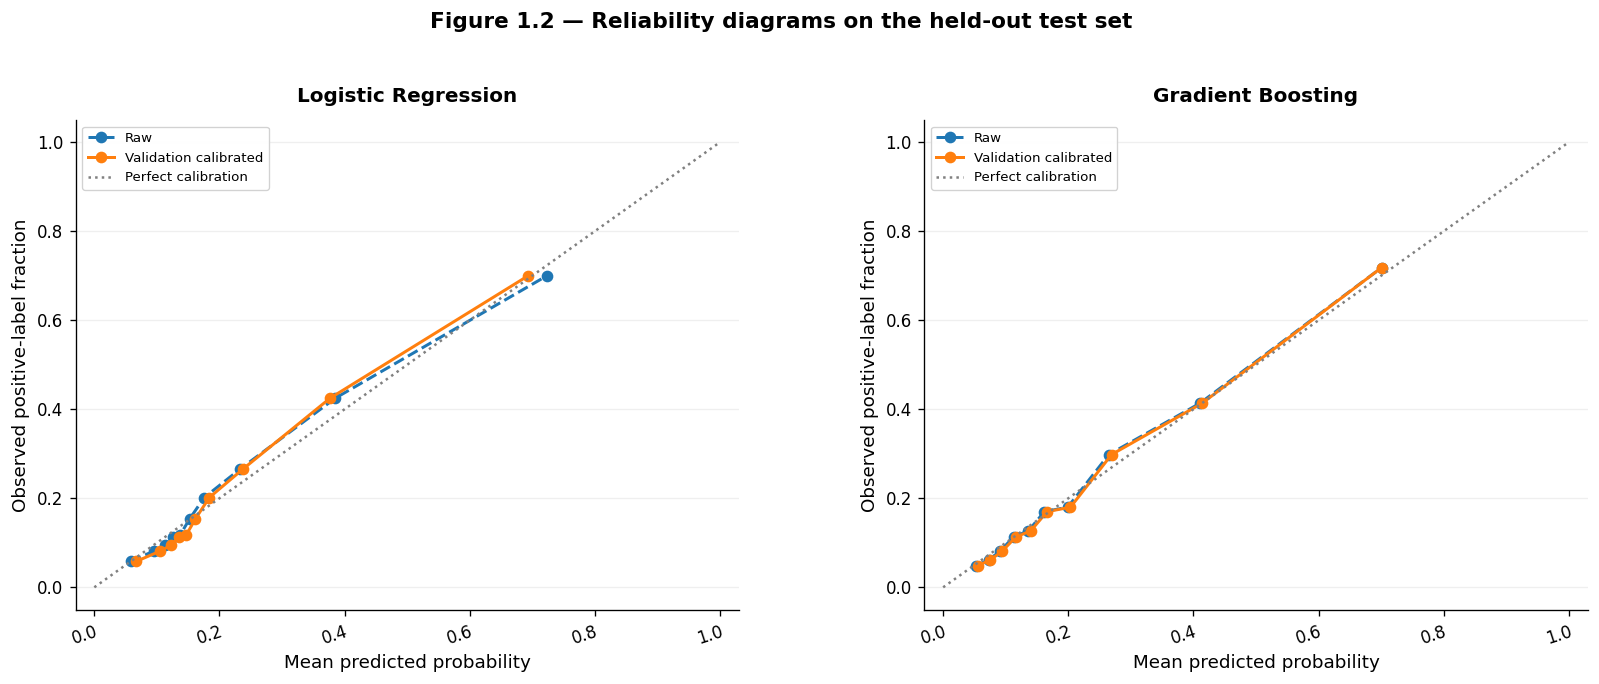

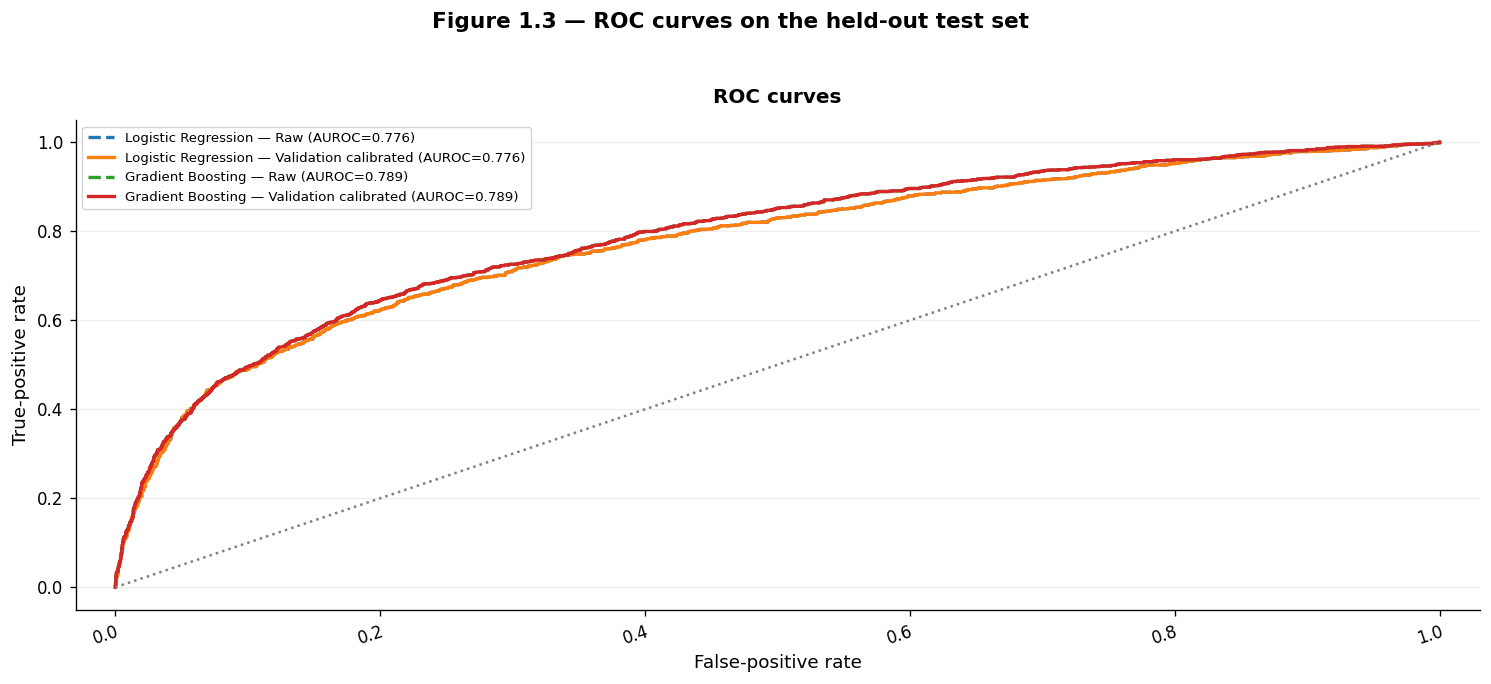

,model,review_budget,cases_per_queue,raw_and_calibrated_overlap,union_count,jaccard_similarity,overlap_share_of_queue,flags_changed,raw_only_flags,calibrated_only_flags
0,Logistic Regression,0.05,300,63,537,0.117318,0.210000,474,237,237
1,Logistic Regression,0.10,600,372,828,0.449275,0.620000,456,228,228
2,Logistic Regression,0.20,1200,977,1423,0.686578,0.814167,446,223,223
3,Gradient Boosting,0.05,300,219,381,0.574803,0.730000,162,81,81
4,Gradient Boosting,0.10,600,527,673,0.783061,0.878333,146,73,73
5,Gradient Boosting,0.20,1200,1124,1276,0.880878,0.936667,152,76,76


In [8]:
def select_uncertainty(probs, k, threshold=DECISION_THRESHOLD):
    probabilities = np.asarray(probs, dtype=float)
    selected = np.zeros(len(probabilities), dtype=bool)
    if k <= 0:
        return selected
    order = np.argsort(np.abs(probabilities - threshold), kind='mergesort')
    selected[order[:min(k, len(probabilities))]] = True
    return selected


# Figure 1.2: reliability diagrams for raw and calibrated test probabilities.
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, name in zip(axes, MODEL_NAMES):
    res = main_models[name]
    for kind, key, style in [('Raw', 'p_test_raw', '--'),
                             ('Validation calibrated', 'p_test_cal', '-')]:
        frac_pos, mean_pred = calibration_curve(
            y_test, res[key], n_bins=10, strategy='quantile'
        )
        ax.plot(mean_pred, frac_pos, marker='o', linestyle=style,
                linewidth=1.8, label=kind)
    ax.plot([0, 1], [0, 1], color='grey', linestyle=':', label='Perfect calibration')
    ax.set(title=name, xlabel='Mean predicted probability',
           ylabel='Observed positive-label fraction')
    ax.set_title(name, fontsize=12, pad=11)
    ax.legend(frameon=False, fontsize=8)
    clean_axis(ax)
fig.suptitle('Figure 1.2 — Reliability diagrams on the held-out test set',
             fontsize=14, fontweight='bold', y=0.98)
# Reserve a separate title band above both subplot headings.
# This spacing is preserved in the PDF export and Kaggle inline preview.
fig.tight_layout(rect=[0.02, 0.02, 0.98, 0.86], w_pad=3.0, h_pad=2.0)
save_figure('Figure_1.2_reliability_diagrams', fig)

# Figure 1.3: ROC curves for raw and calibrated test probabilities.
fig, ax = plt.subplots(figsize=(8, 6))
for name, res in main_models.items():
    for kind, key, style in [('Raw', 'p_test_raw', '--'),
                             ('Validation calibrated', 'p_test_cal', '-')]:
        fpr, tpr, _ = roc_curve(y_test, res[key])
        auc_value = roc_auc_score(y_test, res[key])
        ax.plot(fpr, tpr, linestyle=style, linewidth=2,
                label=f'{name} — {kind} (AUROC={auc_value:.3f})')
ax.plot([0, 1], [0, 1], color='grey', linestyle=':')
ax.set(title='ROC curves', xlabel='False-positive rate', ylabel='True-positive rate')
ax.legend(frameon=False, fontsize=8)
clean_axis(ax)
fig.suptitle('Figure 1.3 — ROC curves on the held-out test set',
             fontsize=13, fontweight='bold')
fig.tight_layout(rect=[0.02, 0.02, 0.98, 0.87], w_pad=2.5, h_pad=2.0)
save_figure('Figure_1.3_ROC_curves', fig)

# Table 1.4: compare raw and calibrated queues at each required review budget.
overlap_rows = []
for model_name, res in main_models.items():
    for capacity in [0.05, 0.10, 0.20]:
        queue_size = int(round(capacity * len(y_test)))
        raw_flags = select_uncertainty(res['p_test_raw'], queue_size)
        cal_flags = select_uncertainty(res['p_test_cal'], queue_size)
        intersection = int((raw_flags & cal_flags).sum())
        union = int((raw_flags | cal_flags).sum())
        overlap_rows.append({
            'model': model_name,
            'review_budget': capacity,
            'cases_per_queue': queue_size,
            'raw_and_calibrated_overlap': intersection,
            'union_count': union,
            'jaccard_similarity': intersection / union if union else np.nan,
            'overlap_share_of_queue': intersection / queue_size if queue_size else np.nan,
            'flags_changed': int((raw_flags != cal_flags).sum()),
            'raw_only_flags': int((raw_flags & ~cal_flags).sum()),
            'calibrated_only_flags': int((cal_flags & ~raw_flags).sum())
        })
rq1_overlap = pd.DataFrame(overlap_rows)
display_and_save('Table_1.4_review_queue_overlap', rq1_overlap)


## 7. RQ2 — Fairness and review rates

**Research question:** How do false-positive rates, false-negative rates, calibration and review burden differ across recorded sex and age groups?

**Purpose:** Audit the selected primary model on the test set. Use the three age groups: 21–30, 31–45 and 46+. Use a 20% uncertainty queue for the review-rate comparison. Report the sample count for every group. Keep the sex-by-age intersection audit as an Extra result.


,grouping,group,n,n_positive,n_negative,positive_label_rate,mean_predicted_probability,Brier score,ECE (10 bins),FPR,FNR,precision,positive_prediction_rate,reviewed_n,review_rate,share_of_all_reviews
0,Recorded sex,Male,2372,572,1800,0.241147,0.231364,0.145336,0.024390,0.364444,0.232517,0.400913,0.461636,516,0.217538,0.430000
1,Recorded sex,Female,3628,755,2873,0.208104,0.218345,0.123737,0.022561,0.350853,0.241060,0.362429,0.435777,684,0.188534,0.570000
2,Age group,21–30,2181,467,1714,0.214122,0.229059,0.129044,0.024242,0.359977,0.211991,0.373604,0.451628,461,0.211371,0.384167
3,Age group,46+,999,269,730,0.269269,0.246681,0.153239,0.026865,0.400000,0.241636,0.411290,0.496496,207,0.207207,0.172500
4,Age group,31–45,2820,591,2229,0.209574,0.210972,0.127349,0.015145,0.338717,0.255499,0.368201,0.423759,532,0.188652,0.443333


Sex group sample counts: Male: n=2,372; Female: n=3,628
Age group sample counts: 21–30: n=2,181; 46+: n=999; 31–45: n=2,820


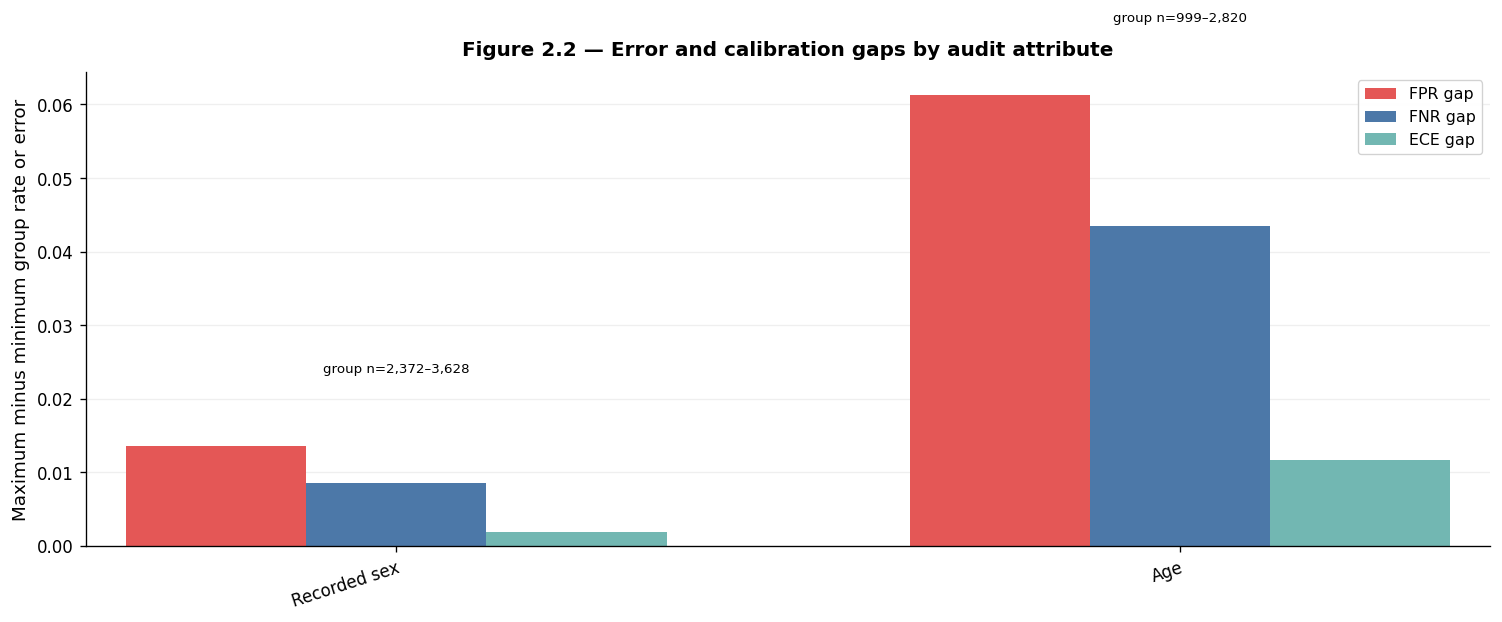

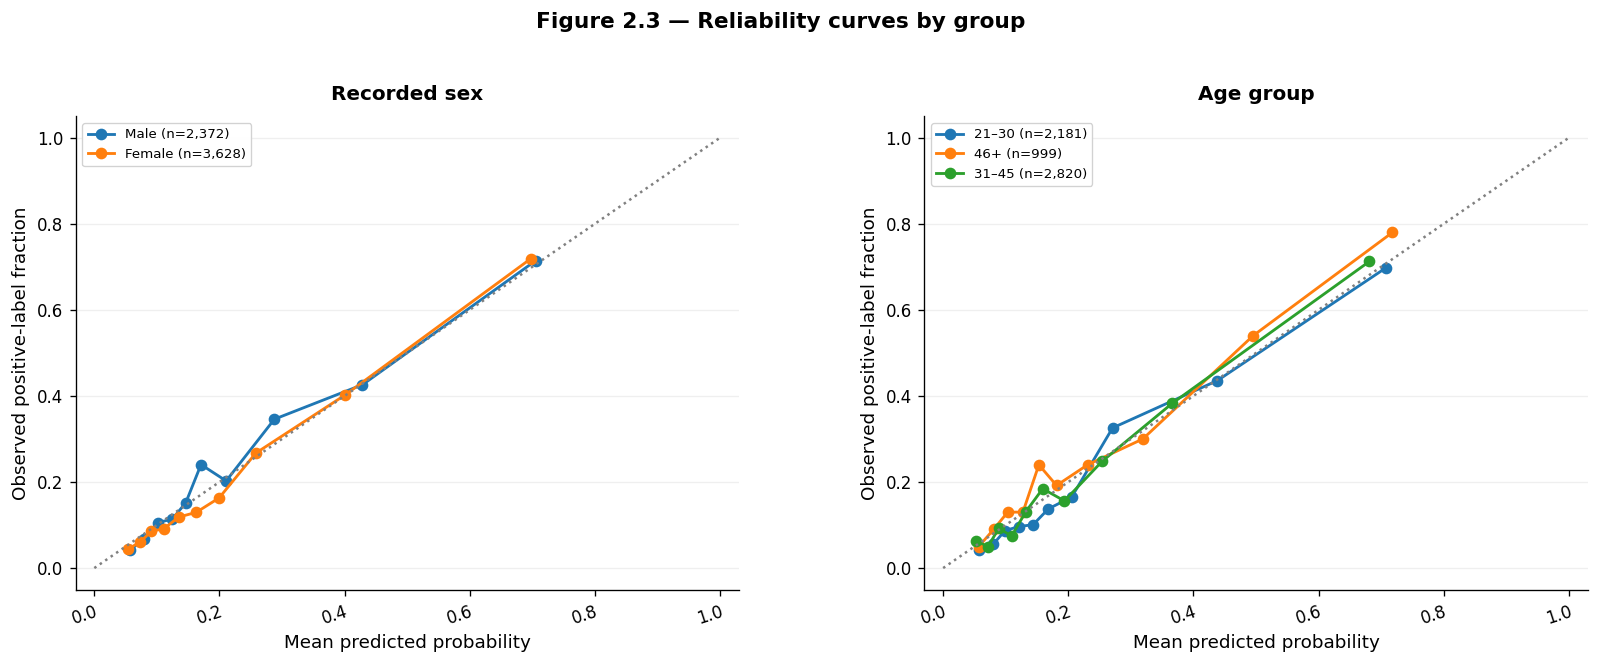

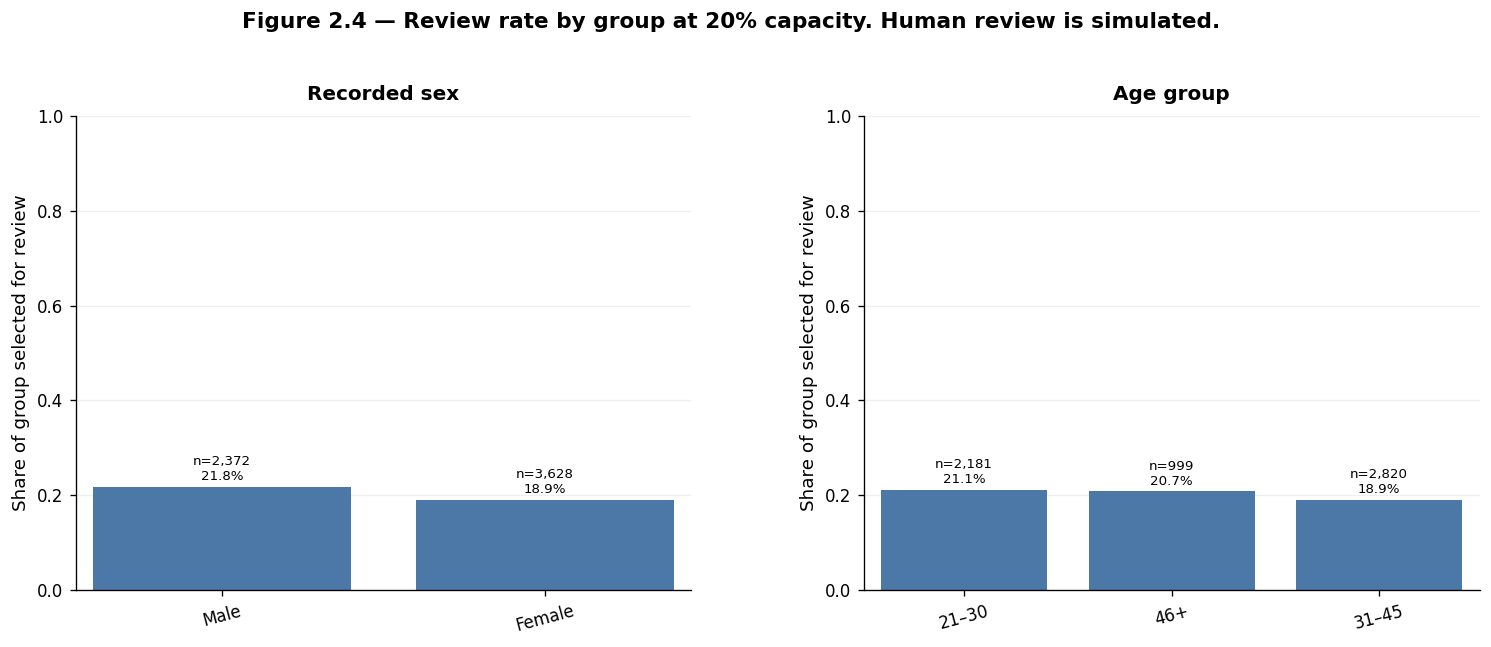

WindowsPath('c:/Users/dheer/Projects/DSC02/PW26 - Interdisciplinary Elective AI, Power & Responsibility – Governing Intell/Dataset/credit_review_work/credit_review_results/figures/Figure_2.4_review_rate_by_group.pdf')

In [9]:
test_audit = credit_df.iloc[idx_test].reset_index(drop=True)


def group_audit(y_true, probs, group_values, group_label, threshold=DECISION_THRESHOLD,
                reviewed=None):
    y_true = np.asarray(y_true).astype(int)
    probs = np.asarray(probs).astype(float)
    groups = pd.Series(group_values).reset_index(drop=True)
    pred = (probs >= threshold).astype(int)
    if reviewed is None:
        reviewed = np.zeros(len(y_true), dtype=bool)
    reviewed = np.asarray(reviewed).astype(bool)
    rows = []
    for group in groups.dropna().drop_duplicates().tolist():
        mask = (groups == group).to_numpy()
        yy = y_true[mask]
        pp = probs[mask]
        pr = pred[mask]
        tn, fp, fn, tp = confusion_matrix(yy, pr, labels=[0, 1]).ravel()
        rows.append({
            'grouping': group_label,
            'group': str(group),
            'n': int(mask.sum()),
            'n_positive': int((yy == 1).sum()),
            'n_negative': int((yy == 0).sum()),
            'positive_label_rate': float(yy.mean()),
            'mean_predicted_probability': float(pp.mean()),
            'Brier score': brier_score_loss(yy, pp),
            'ECE (10 bins)': expected_calibration_error(yy, pp, 10),
            'FPR': fp / (fp + tn) if (fp + tn) else np.nan,
            'FNR': fn / (fn + tp) if (fn + tp) else np.nan,
            'precision': precision_score(yy, pr, zero_division=0),
            'positive_prediction_rate': float(pr.mean()),
            'reviewed_n': int(reviewed[mask].sum()),
            'review_rate': float(reviewed[mask].mean()),
            'share_of_all_reviews': float(reviewed[mask].sum() / max(reviewed.sum(), 1))
        })
    return pd.DataFrame(rows)


RQ2_REVIEW_BUDGET = 0.20
rq2_review_n = int(round(RQ2_REVIEW_BUDGET * len(y_test)))
rq2_review_flags = select_uncertainty(PRIMARY_PROBS, rq2_review_n)
sex_audit = group_audit(y_test, PRIMARY_PROBS, test_audit['sex_group'],
                        'Recorded sex', reviewed=rq2_review_flags)
age_audit = group_audit(y_test, PRIMARY_PROBS, test_audit['age_group'],
                        'Age group', reviewed=rq2_review_flags)
rq2_group_rates = pd.concat([sex_audit, age_audit], ignore_index=True)
display_and_save('Table_2.1_group_rates', rq2_group_rates)
print('Sex group sample counts:', group_count_text(test_audit['sex_group']))
print('Age group sample counts:', group_count_text(test_audit['age_group']))

# Figure 2.2: gaps between groups for FPR, FNR and ECE.
gap_rows = []
for frame, label in [(sex_audit, 'Recorded sex'), (age_audit, 'Age')]:
    gap_rows.append({
        'grouping': label,
        'FPR gap': frame['FPR'].max() - frame['FPR'].min(),
        'FNR gap': frame['FNR'].max() - frame['FNR'].min(),
        'ECE gap': frame['ECE (10 bins)'].max() - frame['ECE (10 bins)'].min(),
        'smallest_group_n': int(frame['n'].min()),
        'largest_group_n': int(frame['n'].max())
    })
rq2_gaps = pd.DataFrame(gap_rows)
fig, ax = plt.subplots(figsize=(9, 5))
x = np.arange(len(rq2_gaps))
width = 0.23
for offset, metric, color in [(-width, 'FPR gap', '#E45756'),
                              (0, 'FNR gap', '#4C78A8'),
                              (width, 'ECE gap', '#72B7B2')]:
    ax.bar(x + offset, rq2_gaps[metric], width, label=metric, color=color)
for i, row in rq2_gaps.iterrows():
    ax.text(i, max(row['FPR gap'], row['FNR gap'], row['ECE gap']) + 0.01,
            f"group n={row['smallest_group_n']:,}–{row['largest_group_n']:,}",
            ha='center', fontsize=8)
ax.set_xticks(x, rq2_gaps['grouping'])
ax.set_ylabel('Maximum minus minimum group rate or error')
ax.set_title('Figure 2.2 — Error and calibration gaps by audit attribute')
ax.legend(frameon=False)
clean_axis(ax)
fig.tight_layout()
save_figure('Figure_2.2_gap_bars_sex_age', fig)

# Figure 2.3: group reliability curves. The legend reports each group sample count.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, group_values, group_label in [
    (axes[0], test_audit['sex_group'], 'Recorded sex'),
    (axes[1], test_audit['age_group'], 'Age group')
]:
    groups = pd.Series(group_values).reset_index(drop=True)
    for group in groups.dropna().drop_duplicates().tolist():
        mask = (groups == group).to_numpy()
        frac_pos, mean_pred = calibration_curve(
            np.asarray(y_test)[mask], np.asarray(PRIMARY_PROBS)[mask],
            n_bins=10, strategy='quantile'
        )
        ax.plot(mean_pred, frac_pos, marker='o', linewidth=1.7,
                label=f'{group} (n={int(mask.sum()):,})')
    ax.plot([0, 1], [0, 1], color='grey', linestyle=':')
    ax.set(title=group_label, xlabel='Mean predicted probability',
           ylabel='Observed positive-label fraction')
    ax.legend(frameon=False, fontsize=8)
    clean_axis(ax)
fig.suptitle('Figure 2.3 — Reliability curves by group', fontsize=13, fontweight='bold')
fig.tight_layout(rect=[0.02, 0.02, 0.98, 0.87], w_pad=2.5, h_pad=2.0)
save_figure('Figure_2.3_group_reliability_curves', fig)

# Figure 2.4: review rate by group at the 20% overall budget.
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, frame, label in [(axes[0], sex_audit, 'Recorded sex'),
                         (axes[1], age_audit, 'Age group')]:
    bars = ax.bar(frame['group'].astype(str), frame['review_rate'],
                  color='#4C78A8')
    ax.set(title=label, ylabel='Share of group selected for review', ylim=(0, 1))
    ax.tick_params(axis='x', rotation=15)
    for bar, row in zip(bars, frame.itertuples()):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.015,
                f'n={row.n:,}\n{row.review_rate:.1%}', ha='center', fontsize=8)
    clean_axis(ax)
fig.suptitle('Figure 2.4 — Review rate by group at 20% capacity. Human review is simulated.',
             fontsize=13, fontweight='bold')
fig.tight_layout(rect=[0.02, 0.02, 0.98, 0.87], w_pad=2.5, h_pad=2.0)
save_figure('Figure_2.4_review_rate_by_group', fig)


## 8. RQ3 — Six feature configurations

**Research question:** How do repayment history, credit limits, billing amounts and payment amounts affect predictive performance and group disparities, with and without sex and age as inputs?

**Purpose:** Compare six configurations only. They are the full feature set, minus repayment history, minus bill amounts, minus payment amounts, minus sex and age, and minus credit limit. Fit each model with the same train, validation and test rows. Fit calibration on validation predictions only. Feature importance is not a causal effect.

**New ablation:** `Minus credit limit` excludes `LIMIT_BAL`; refits each model with the same train/validation/test index partitions and refits its Platt map only on validation data. All feature effects are predictive associations, not causal estimates.


In [10]:
FEATURE_CONFIGURATIONS = OrderedDict([
    ('Full', []),
    ('Minus repayment history', ['PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6']),
    ('Minus bill amounts', [c for c in FEATURE_COLUMNS if c.startswith('BILL_AMT')]),
    ('Minus payment amounts', [c for c in FEATURE_COLUMNS if c.startswith('PAY_AMT')]),
    ('Minus sex and age', ['SEX', 'AGE']),
    ('Minus credit limit', ['LIMIT_BAL'])
])


def group_fnr_gap(y_true, probs, groups, threshold=DECISION_THRESHOLD):
    y_true = np.asarray(y_true).astype(int)
    predictions = (np.asarray(probs) >= threshold).astype(int)
    group_values = pd.Series(groups).reset_index(drop=True)
    rates = []
    for group in group_values.dropna().drop_duplicates().tolist():
        mask = (group_values == group).to_numpy()
        positives = y_true[mask] == 1
        if positives.any():
            rates.append(float(np.mean(predictions[mask][positives] == 0)))
    return float(max(rates) - min(rates)) if len(rates) >= 2 else np.nan


sex_group_counts = test_audit['sex_group'].astype(str).value_counts().to_dict()
age_group_counts = test_audit['age_group'].astype(str).value_counts().to_dict()
rq3_rows = []
for model_name in MODEL_NAMES:
    full_auc = roc_auc_score(y_test, main_models[model_name]['p_test_cal'])
    for config_name, removed_columns in FEATURE_CONFIGURATIONS.items():
        columns = [c for c in FEATURE_COLUMNS if c not in removed_columns]
        if config_name == 'Full':
            result = main_models[model_name]
        else:
            result = fit_with_validation_calibration(
                model_name,
                X_train[columns], y_train,
                X_val[columns], y_val,
                X_test[columns],
                categorical_cols=[c for c in MAIN_CATEGORICAL if c in columns]
            )
        probabilities = result['p_test_cal']
        metrics = classification_metrics(y_test, probabilities)
        rq3_rows.append({
            'model': model_name,
            'feature_configuration': config_name,
            'removed_columns': ', '.join(removed_columns) if removed_columns else 'None',
            'n_input_features': len(columns),
            'AUROC': metrics['AUROC'],
            'AUROC_drop_vs_full': full_auc - metrics['AUROC'],
            'Average precision': metrics['Average precision'],
            'Brier score': metrics['Brier score'],
            'FNR': metrics['FNR'],
            'FNR_gap_recorded_sex': group_fnr_gap(y_test, probabilities, test_audit['sex_group']),
            'FNR_gap_age': group_fnr_gap(y_test, probabilities, test_audit['age_group']),
            'sex_group_counts': json.dumps(sex_group_counts, ensure_ascii=False),
            'age_group_counts': json.dumps(age_group_counts, ensure_ascii=False)
        })
        print('Completed:', model_name, '|', config_name)

rq3_configurations = pd.DataFrame(rq3_rows)
display_and_save('Table_3.1_feature_configurations', rq3_configurations)


Completed: Logistic Regression | Full
Completed: Logistic Regression | Minus repayment history
Completed: Logistic Regression | Minus bill amounts
Completed: Logistic Regression | Minus payment amounts
Completed: Logistic Regression | Minus sex and age
Completed: Logistic Regression | Minus credit limit
Completed: Gradient Boosting | Full
Completed: Gradient Boosting | Minus repayment history
Completed: Gradient Boosting | Minus bill amounts
Completed: Gradient Boosting | Minus payment amounts
Completed: Gradient Boosting | Minus sex and age
Completed: Gradient Boosting | Minus credit limit


,model,feature_configuration,removed_columns,n_input_features,AUROC,AUROC_drop_vs_full,Average precision,Brier score,FNR,FNR_gap_recorded_sex,FNR_gap_age,sex_group_counts,age_group_counts
0,Logistic Regression,Full,None,23,0.775854,0.000000,0.558513,0.134735,0.262999,0.081230,0.059190,"{""Female"": 3628, ""Male"": 2372}","{""31–45"": 2820, ""21–30"": 2181, ""46+"": 999}"
1,Logistic Regression,Minus repayment history,"PAY_0, PAY_2, PAY_3, PAY_4, PAY_5, PAY_6",17,0.658973,0.116881,0.333221,0.163556,0.132630,0.061038,0.076334,"{""Female"": 3628, ""Male"": 2372}","{""31–45"": 2820, ""21–30"": 2181, ""46+"": 999}"
2,Logistic Regression,Minus bill amounts,"BILL_AMT1, BILL_AMT2, BILL_AMT3, BILL_AMT4, BI...",17,0.771200,0.004654,0.555451,0.135206,0.272796,0.083085,0.059882,"{""Female"": 3628, ""Male"": 2372}","{""31–45"": 2820, ""21–30"": 2181, ""46+"": 999}"
3,Logistic Regression,Minus payment amounts,"PAY_AMT1, PAY_AMT2, PAY_AMT3, PAY_AMT4, PAY_AM...",17,0.769351,0.006503,0.553899,0.135322,0.275057,0.068622,0.072060,"{""Female"": 3628, ""Male"": 2372}","{""31–45"": 2820, ""21–30"": 2181, ""46+"": 999}"
4,Logistic Regression,Minus sex and age,"SEX, AGE",21,0.773353,0.002501,0.556840,0.134987,0.281839,0.006796,0.056523,"{""Female"": 3628, ""Male"": 2372}","{""31–45"": 2820, ""21–30"": 2181, ""46+"": 999}"
5,Logistic Regression,Minus credit limit,LIMIT_BAL,22,0.768668,0.007186,0.558063,0.135268,0.292389,0.052994,0.076136,"{""Female"": 3628, ""Male"": 2372}","{""31–45"": 2820, ""21–30"": 2181, ""46+"": 999}"
6,Gradient Boosting,Full,None,23,0.788785,0.000000,0.571930,0.132276,0.237378,0.008542,0.043508,"{""Female"": 3628, ""Male"": 2372}","{""31–45"": 2820, ""21–30"": 2181, ""46+"": 999}"
7,Gradient Boosting,Minus repayment history,"PAY_0, PAY_2, PAY_3, PAY_4, PAY_5, PAY_6",17,0.733173,0.055612,0.448623,0.149705,0.211002,0.020567,0.044753,"{""Female"": 3628, ""Male"": 2372}","{""31–45"": 2820, ""21–30"": 2181, ""46+"": 999}"
8,Gradient Boosting,Minus bill amounts,"BILL_AMT1, BILL_AMT2, BILL_AMT3, BILL_AMT4, BI...",17,0.784416,0.004369,0.564446,0.132995,0.227581,0.003615,0.057254,"{""Female"": 3628, ""Male"": 2372}","{""31–45"": 2820, ""21–30"": 2181, ""46+"": 999}"
9,Gradient Boosting,Minus payment amounts,"PAY_AMT1, PAY_AMT2, PAY_AMT3, PAY_AMT4, PAY_AM...",17,0.790379,-0.001594,0.572550,0.132561,0.233610,0.004992,0.034149,"{""Female"": 3628, ""Male"": 2372}","{""31–45"": 2820, ""21–30"": 2181, ""46+"": 999}"


## 9. RQ3 — Performance and group gaps

**Purpose:** Save the three required RQ3 figures. Figure 3.2 shows the AUROC drop from the full model. Figure 3.3 shows the sex and age FNR gaps for each configuration. Figure 3.4 shows Logistic Regression coefficients and permutation importance for the selected primary model. Feature importance is not a causal effect.


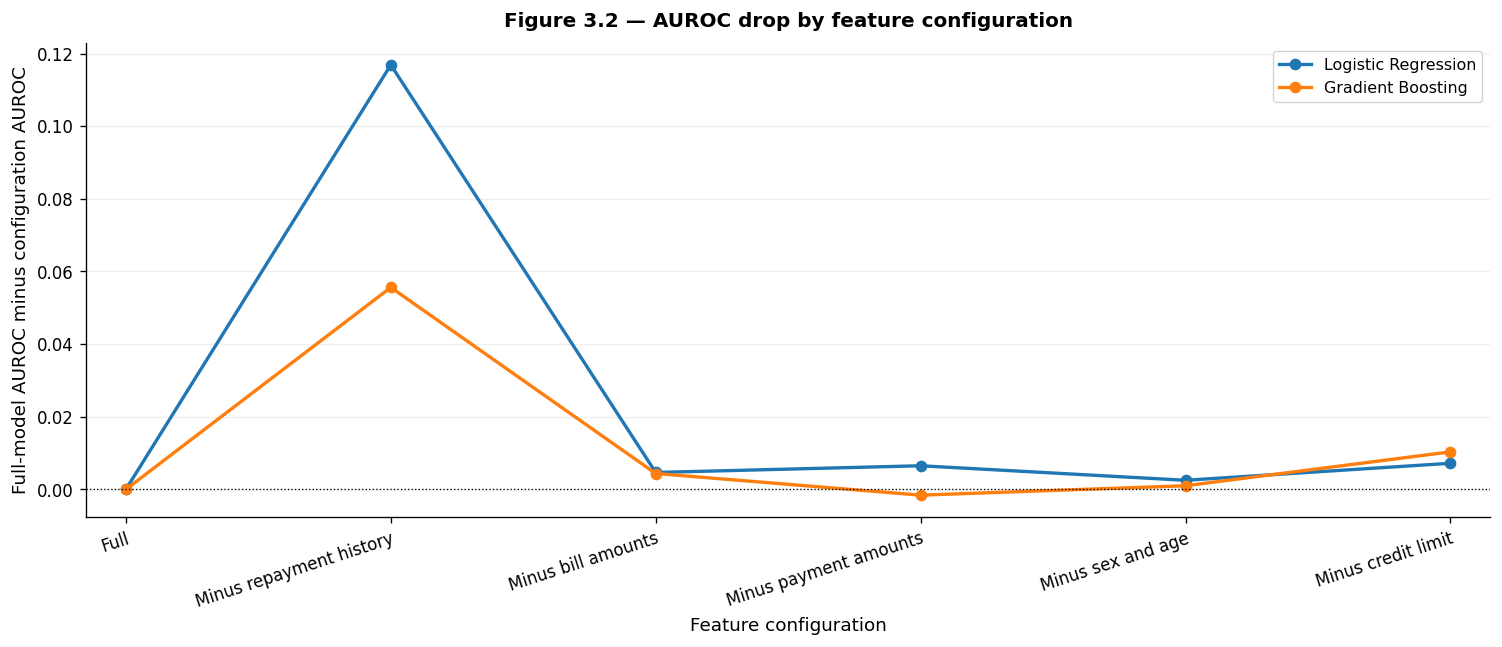

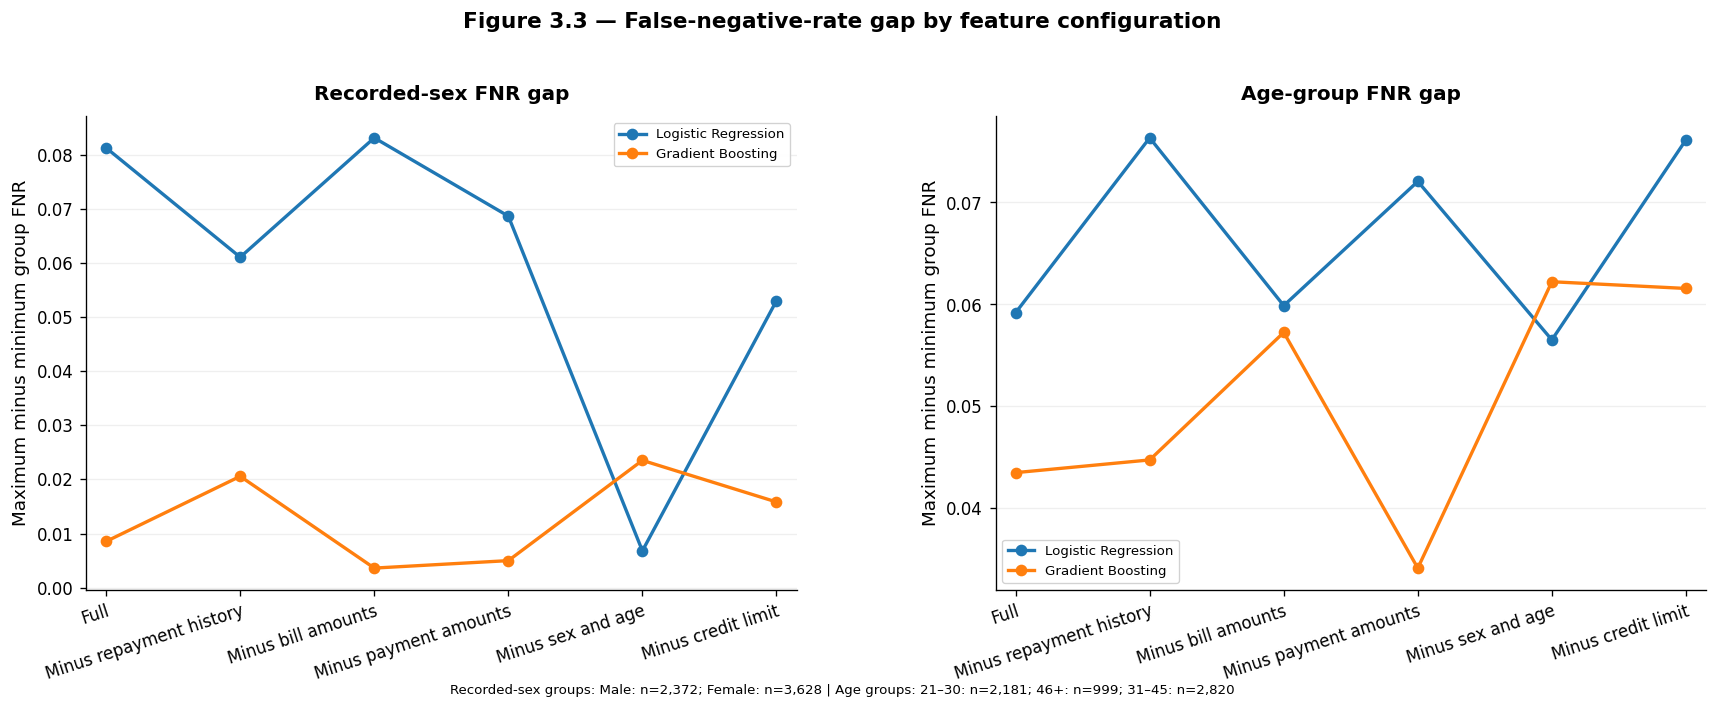

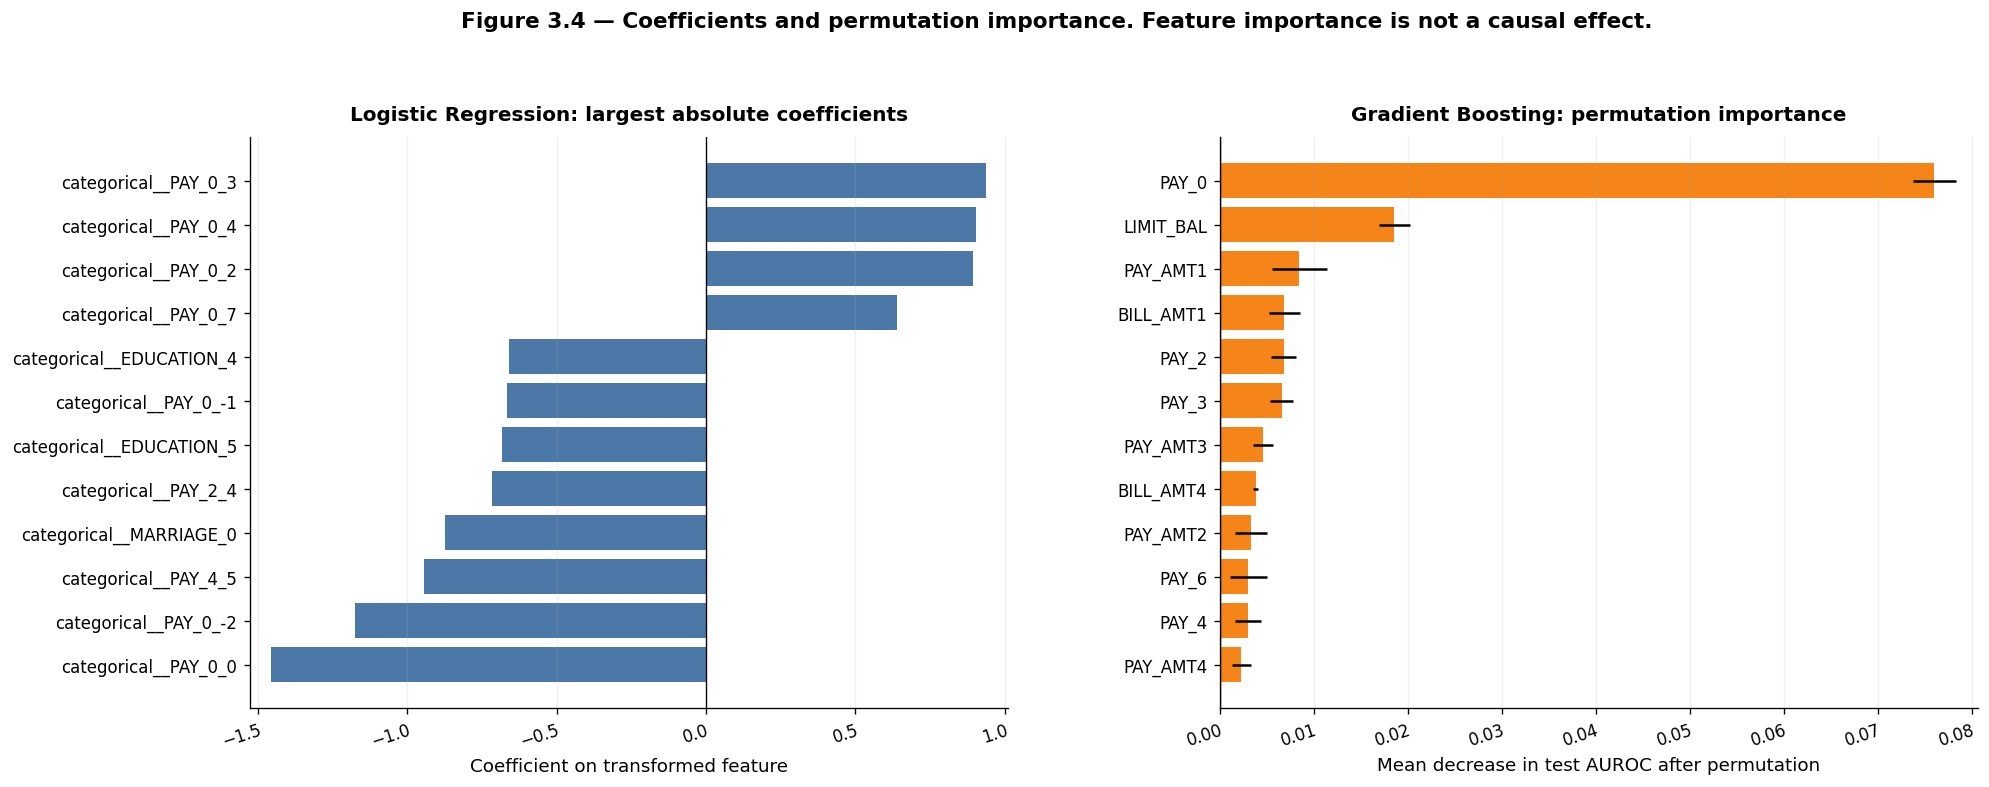

WindowsPath('c:/Users/dheer/Projects/DSC02/PW26 - Interdisciplinary Elective AI, Power & Responsibility – Governing Intell/Dataset/credit_review_work/credit_review_results/figures/Figure_3.4_coefficients_permutation_importance.pdf')

In [11]:
# Figure 3.2: AUROC drop from the full feature configuration.
fig, ax = plt.subplots(figsize=(11, 5))
plot_order = list(FEATURE_CONFIGURATIONS.keys())
for model_name in MODEL_NAMES:
    frame = rq3_configurations[rq3_configurations['model'] == model_name].copy()
    frame['feature_configuration'] = pd.Categorical(
        frame['feature_configuration'], categories=plot_order, ordered=True
    )
    frame = frame.sort_values('feature_configuration')
    ax.plot(frame['feature_configuration'].astype(str), frame['AUROC_drop_vs_full'],
            marker='o', linewidth=2, label=model_name)
ax.axhline(0, color='black', linewidth=0.8, linestyle=':')
ax.set_ylabel('Full-model AUROC minus configuration AUROC')
ax.set_xlabel('Feature configuration')
ax.tick_params(axis='x', rotation=18)
ax.legend(frameon=False)
ax.set_title('Figure 3.2 — AUROC drop by feature configuration')
clean_axis(ax)
fig.tight_layout()
save_figure('Figure_3.2_ROC_AUC_drop', fig)

# Figure 3.3: sex and age FNR gaps for all six configurations.
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, metric, title in [
    (axes[0], 'FNR_gap_recorded_sex', 'Recorded-sex FNR gap'),
    (axes[1], 'FNR_gap_age', 'Age-group FNR gap')
]:
    for model_name in MODEL_NAMES:
        frame = rq3_configurations[rq3_configurations['model'] == model_name].copy()
        frame['feature_configuration'] = pd.Categorical(
            frame['feature_configuration'], categories=plot_order, ordered=True
        )
        frame = frame.sort_values('feature_configuration')
        ax.plot(frame['feature_configuration'].astype(str), frame[metric],
                marker='o', linewidth=2, label=model_name)
    ax.set(title=title, ylabel='Maximum minus minimum group FNR', xlabel='')
    ax.tick_params(axis='x', rotation=18)
    ax.legend(frameon=False, fontsize=8)
    clean_axis(ax)
fig.suptitle('Figure 3.3 — False-negative-rate gap by feature configuration',
             fontsize=13, fontweight='bold')
fig.text(0.5, 0.01, 'Recorded-sex groups: ' + group_count_text(test_audit['sex_group']) +
         ' | Age groups: ' + group_count_text(test_audit['age_group']),
         ha='center', fontsize=8)
fig.tight_layout(rect=[0, 0.05, 1, 0.92])
save_figure('Figure_3.3_FNR_gap_by_configuration', fig)

# Figure 3.4: Logistic Regression coefficients and permutation importance.
logistic_pipeline = main_models['Logistic Regression']['model']
feature_names = logistic_pipeline.named_steps['preprocess'].get_feature_names_out()
coefficient_values = logistic_pipeline.named_steps['model'].coef_.ravel()
coefficient_frame = pd.DataFrame({
    'feature': feature_names,
    'coefficient': coefficient_values
})
coefficient_frame['absolute_coefficient'] = coefficient_frame['coefficient'].abs()
coefficient_frame = coefficient_frame.nlargest(12, 'absolute_coefficient').sort_values('coefficient')

permutation_result = permutation_importance(
    main_models[PRIMARY_MODEL_NAME]['model'], X_test, y_test,
    n_repeats=5, random_state=SEED, scoring='roc_auc', n_jobs=1
)
permutation_frame = pd.DataFrame({
    'feature': FEATURE_COLUMNS,
    'permutation_importance_mean': permutation_result.importances_mean,
    'permutation_importance_sd': permutation_result.importances_std
}).nlargest(12, 'permutation_importance_mean').sort_values('permutation_importance_mean')

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
axes[0].barh(coefficient_frame['feature'], coefficient_frame['coefficient'], color='#4C78A8')
axes[0].axvline(0, color='black', linewidth=0.8)
axes[0].set(title='Logistic Regression: largest absolute coefficients',
            xlabel='Coefficient on transformed feature')
axes[1].barh(permutation_frame['feature'],
             permutation_frame['permutation_importance_mean'],
             xerr=permutation_frame['permutation_importance_sd'], color='#F58518')
axes[1].axvline(0, color='black', linewidth=0.8)
axes[1].set(title=f'{PRIMARY_MODEL_NAME}: permutation importance',
            xlabel='Mean decrease in test AUROC after permutation')
for ax in axes:
    ax.grid(axis='x', alpha=0.2)
    ax.spines[['top', 'right']].set_visible(False)
fig.suptitle('Figure 3.4 — Coefficients and permutation importance. Feature importance is not a causal effect.',
             fontsize=12, fontweight='bold')
fig.tight_layout(rect=[0.02, 0.02, 0.98, 0.87], w_pad=2.5, h_pad=2.0)
save_figure('Figure_3.4_coefficients_permutation_importance', fig)


## 10. RQ4 — Review policies and simulated reviewer

**Research question:** As review capacity increases, how much net value does human review add? Can equal age-group review rates reduce disparities without a large cost?

**Purpose:** Define four policies. A reviewer sees the true label only inside the simulation. The reviewer reports that label correctly with probability `1 - error_rate`. The same error rate applies to both classes. Errors are independent. A review decision replaces the automatic decision. The RQ4 capacity curve uses the 0% reviewer-error scenario. RQ5 tests all five requested error rates.


In [12]:
def group_aware_uncertainty(probs, age_groups, k, threshold=DECISION_THRESHOLD):
    """Give each age group an equal review rate, with integer quota rounding."""
    probabilities = np.asarray(probs, dtype=float)
    groups = pd.Series(age_groups).reset_index(drop=True).astype(str)
    selected = np.zeros(len(probabilities), dtype=bool)
    if k <= 0 or len(probabilities) == 0:
        return selected

    group_indices = {
        group: np.flatnonzero(groups.to_numpy() == group)
        for group in groups.drop_duplicates().tolist()
    }
    exact_quotas = {group: k * len(indices) / len(probabilities)
                    for group, indices in group_indices.items()}
    allocation = {group: int(np.floor(quota))
                  for group, quota in exact_quotas.items()}
    remaining = k - sum(allocation.values())
    quota_order = sorted(
        exact_quotas,
        key=lambda group: (-(exact_quotas[group] - allocation[group]), -len(group_indices[group]), str(group))
    )
    for group in quota_order:
        if remaining <= 0:
            break
        if allocation[group] < len(group_indices[group]):
            allocation[group] += 1
            remaining -= 1

    for group, indices in group_indices.items():
        quota = allocation[group]
        if quota > 0:
            distance = np.abs(probabilities[indices] - threshold)
            order = np.argsort(distance, kind='mergesort')
            selected[indices[order[:quota]]] = True
    return selected


def select_policy(policy, probs, k, age_groups=None, seed=SEED):
    n = len(probs)
    if policy == 'No review' or k <= 0:
        return np.zeros(n, dtype=bool)
    if policy == 'Random review':
        mask = np.zeros(n, dtype=bool)
        mask[np.random.default_rng(seed).permutation(n)[:k]] = True
        return mask
    if policy == 'Uncertainty review':
        return select_uncertainty(probs, k)
    if policy == 'Group-aware age review':
        return group_aware_uncertainty(probs, age_groups, k)
    raise ValueError('Unknown review policy: ' + str(policy))


def _group_rate_gap(y_true, predictions, groups, target_value, prediction_value):
    y=np.asarray(y_true,dtype=np.int8); pred=np.asarray(predictions,dtype=np.int8)
    group=np.asarray(groups).astype(str)
    valid=[]
    for label in np.unique(group):
        index=(group==label)&(y==target_value)
        if index.any(): valid.append(float(np.mean(pred[index]==prediction_value)))
    return (max(valid)-min(valid)) if len(valid)>=2 else np.nan


def fnr_gap_from_predictions(y_true,predictions,groups):
    return _group_rate_gap(y_true,predictions,groups,1,0)


def fpr_gap_from_predictions(y_true,predictions,groups):
    return _group_rate_gap(y_true,predictions,groups,0,1)


def review_rate_gap(reviewed,groups):
    flags=np.asarray(reviewed,dtype=bool); group=np.asarray(groups).astype(str)
    rates=[float(flags[group==label].mean()) for label in np.unique(group)]
    return max(rates)-min(rates) if len(rates)>=2 else np.nan


def simulate_review(y_true, probs, reviewed, reviewer_error_rate,
                    review_cost=REVIEW_COST_PER_CASE, seed=SEED,
                    sex_groups=None, age_groups=None):
    """Simulate independent symmetric reviewer errors on reviewed cases."""
    y = np.asarray(y_true).astype(int)
    probabilities = np.asarray(probs, dtype=float)
    flags = np.asarray(reviewed).astype(bool)
    automatic_prediction = (probabilities >= DECISION_THRESHOLD).astype(int)
    final_prediction = automatic_prediction.copy()

    # The reviewer sees the true label only in this simulation step.
    rng = np.random.default_rng(seed)
    n_reviewed = int(flags.sum())
    if n_reviewed > 0:
        reports_correctly = rng.random(n_reviewed) < (1.0 - reviewer_error_rate)
        reviewer_prediction = np.where(reports_correctly, y[flags], 1 - y[flags])
        final_prediction[flags] = reviewer_prediction

    baseline_errors = automatic_prediction != y
    final_errors = final_prediction != y
    baseline_loss = float(np.where(
        (y == 1) & (automatic_prediction == 0), FALSE_NEGATIVE_COST,
        np.where((y == 0) & (automatic_prediction == 1), FALSE_POSITIVE_COST, 0.0)
    ).sum())
    final_loss = float(np.where(
        (y == 1) & (final_prediction == 0), FALSE_NEGATIVE_COST,
        np.where((y == 0) & (final_prediction == 1), FALSE_POSITIVE_COST, 0.0)
    ).sum())
    total_review_cost = float(n_reviewed * review_cost)
    total_cost = final_loss + total_review_cost

    metrics = {
        'n_reviewed': n_reviewed,
        'review_rate': float(flags.mean()),
        'baseline_weighted_loss': baseline_loss,
        'final_weighted_loss': final_loss,
        'review_cost_total': total_review_cost,
        'total_cost_including_review': total_cost,
        'net_value_per_1000': (baseline_loss - total_cost) / len(y) * 1000,
        'n_decision_changes': int(np.sum(flags & (final_prediction != automatic_prediction))),
        'baseline_errors_corrected': int(np.sum(flags & baseline_errors & ~final_errors)),
        'errors_introduced': int(np.sum(flags & ~baseline_errors & final_errors))
    }
    if age_groups is not None:
        metrics['age_FNR_gap'] = fnr_gap_from_predictions(y, final_prediction, age_groups)
        metrics['age_FPR_gap'] = fpr_gap_from_predictions(y, final_prediction, age_groups)
        metrics['age_review_rate_gap'] = review_rate_gap(flags, age_groups)
    if sex_groups is not None:
        metrics['sex_FNR_gap'] = fnr_gap_from_predictions(y, final_prediction, sex_groups)
        metrics['sex_FPR_gap'] = fpr_gap_from_predictions(y, final_prediction, sex_groups)
        metrics['sex_review_rate_gap'] = review_rate_gap(flags, sex_groups)
    return metrics, final_prediction


POLICIES = [
    'No review',
    'Random review',
    'Uncertainty review',
    'Group-aware age review'
]
TEST_AGE_GROUPS = test_audit['age_group'].astype(str).to_numpy()
TEST_SEX_GROUPS = test_audit['sex_group'].astype(str).to_numpy()
print('Review policies:', POLICIES)
print('Age-group sample counts:', group_count_text(TEST_AGE_GROUPS))
print('Review cost per case:', REVIEW_COST_PER_CASE)
print('RQ4 uses reviewer error rate:', RQ4_REVIEWER_ERROR_RATE)


Review policies: ['No review', 'Random review', 'Uncertainty review', 'Group-aware age review']
Age-group sample counts: 21–30: n=2,181; 46+: n=999; 31–45: n=2,820
Review cost per case: 0.25
RQ4 uses reviewer error rate: 0.0


## 11. RQ4 — Review budgets and evaluation

**Purpose:** Use exactly 0%, 5%, 10% and 20% of the test set. Compare no review, random review, uncertainty review and group-aware age review. The group-aware policy gives each age group an equal review rate. Use 20 repetitions for each policy and budget. RQ4 uses the idealized 0% reviewer-error scenario. Net value includes the 0.25 review cost per case.


In [13]:
rq4_replicate_rows = []
for capacity_index, capacity in enumerate(CAPACITY_LEVELS):
    queue_size = int(round(capacity * len(y_test)))
    for policy_index, policy in enumerate(POLICIES):
        for repetition in range(REVIEW_REPEATS):
            seed = SEED + 10000 * capacity_index + 1000 * policy_index + repetition
            reviewed = select_policy(
                policy, PRIMARY_PROBS, queue_size,
                age_groups=TEST_AGE_GROUPS, seed=seed
            )
            metrics, _ = simulate_review(
                y_test, PRIMARY_PROBS, reviewed,
                reviewer_error_rate=RQ4_REVIEWER_ERROR_RATE,
                seed=seed + 500000,
                sex_groups=TEST_SEX_GROUPS,
                age_groups=TEST_AGE_GROUPS
            )
            rq4_replicate_rows.append({
                'capacity': capacity,
                'policy': policy,
                'repetition': repetition + 1,
                **metrics
            })

rq4_replicates = pd.DataFrame(rq4_replicate_rows)
rq4_metric_columns = [
    'n_reviewed', 'review_rate', 'baseline_weighted_loss', 'final_weighted_loss',
    'review_cost_total', 'total_cost_including_review', 'net_value_per_1000',
    'n_decision_changes', 'baseline_errors_corrected', 'errors_introduced',
    'age_FNR_gap', 'age_FPR_gap', 'age_review_rate_gap',
    'sex_FNR_gap', 'sex_FPR_gap', 'sex_review_rate_gap'
]
rq4_curve_rows = []
for (capacity, policy), frame in rq4_replicates.groupby(['capacity', 'policy'], sort=False):
    row = {'capacity': capacity, 'policy': policy, 'repetitions': len(frame)}
    for metric in rq4_metric_columns:
        row[metric] = frame[metric].mean()
        row[metric + '_sd'] = frame[metric].std(ddof=1) if len(frame) > 1 else 0.0
    rq4_curve_rows.append(row)
rq4_curve = pd.DataFrame(rq4_curve_rows)


### RQ2 supplement — Shared review queues for demographic audits
Queues are selected once per policy/budget/repetition, then the identical boolean selection mask is passed to both recorded-sex and age audits. The **within-group review rate** uses all members of that group as denominator; the **share of review queue** uses all reviewed cases as denominator. Quotas for age-aware selection use age only; sex is never used to select the age-aware queue. Random review is averaged over 20 separately seeded queues.

In [14]:
# RQ2 policy-by-budget demographic review audit. One selection mask is applied to BOTH audits.
# Random policy: independently selected queue for each repetition; report means for review burden.
# All 20 random repetitions have exactly the same per-cell queue size.
rq2_policy_audits=[]
for cap_i,cap in enumerate(CAPACITY_LEVELS):
    k=int(round(cap*len(y_test)))
    for pol_i,pol in enumerate(POLICIES):
        reps=REVIEW_REPEATS if pol=='Random review' else 1
        for rep in range(reps):
            queue=select_policy(pol,PRIMARY_PROBS,k,age_groups=TEST_AGE_GROUPS,seed=SEED+11000000+cap_i*10000+pol_i*1000+rep)
            assert int(queue.sum())==(0 if pol=='No review' else k), (cap,pol)
            sex_view=group_audit(y_test,PRIMARY_PROBS,TEST_SEX_GROUPS,'Recorded sex',reviewed=queue)
            age_view=group_audit(y_test,PRIMARY_PROBS,TEST_AGE_GROUPS,'Age group',reviewed=queue)
            for view in (sex_view,age_view):
                for _,record in view.iterrows():
                    rq2_policy_audits.append({'capacity':cap,'policy':pol,'repetition':rep+1,
                         'queue_size':int(queue.sum()),**record.to_dict()})
rq2_policy_full=pd.DataFrame(rq2_policy_audits)
rq2_policy_summary=(rq2_policy_full.groupby(['capacity','policy','grouping','group'],as_index=False,dropna=False)
    .agg(repetitions=('repetition','nunique'),queue_size=('queue_size','mean'),n=('n','first'),
         n_positive=('n_positive','first'),n_negative=('n_negative','first'),
         FPR=('FPR','first'),FNR=('FNR','first'),Brier_score=('Brier score','first'),
         ECE_10_bins=('ECE (10 bins)','first'),reviewed_n=('reviewed_n','mean'),
         within_group_review_rate=('review_rate','mean'),share_of_queue=('share_of_all_reviews','mean')))
display_and_save('Extra_Table_2.5_policy_budget_group_audit',rq2_policy_summary)
assert ((rq2_policy_full.groupby(['capacity','policy','repetition','grouping']).reviewed_n.sum()
         ==rq2_policy_full.groupby(['capacity','policy','repetition','grouping']).queue_size.first()).all())
print('RQ2: same queue mask audited by sex and by age; within-group rate and share of queue are distinct columns.')


,capacity,policy,grouping,group,repetitions,queue_size,n,n_positive,n_negative,FPR,FNR,Brier_score,ECE_10_bins,reviewed_n,within_group_review_rate,share_of_queue
0,0.0,Group-aware age review,Age group,21–30,1,0.0,2181,467,1714,0.359977,0.211991,0.129044,0.024242,0.0,0.000000,0.000000
1,0.0,Group-aware age review,Age group,31–45,1,0.0,2820,591,2229,0.338717,0.255499,0.127349,0.015145,0.0,0.000000,0.000000
2,0.0,Group-aware age review,Age group,46+,1,0.0,999,269,730,0.400000,0.241636,0.153239,0.026865,0.0,0.000000,0.000000
3,0.0,Group-aware age review,Recorded sex,Female,1,0.0,3628,755,2873,0.350853,0.241060,0.123737,0.022561,0.0,0.000000,0.000000
4,0.0,Group-aware age review,Recorded sex,Male,1,0.0,2372,572,1800,0.364444,0.232517,0.145336,0.024390,0.0,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
75,0.2,Uncertainty review,Age group,21–30,1,1200.0,2181,467,1714,0.359977,0.211991,0.129044,0.024242,461.0,0.211371,0.384167
76,0.2,Uncertainty review,Age group,31–45,1,1200.0,2820,591,2229,0.338717,0.255499,0.127349,0.015145,532.0,0.188652,0.443333
77,0.2,Uncertainty review,Age group,46+,1,1200.0,999,269,730,0.400000,0.241636,0.153239,0.026865,207.0,0.207207,0.172500
78,0.2,Uncertainty review,Recorded sex,Female,1,1200.0,3628,755,2873,0.350853,0.241060,0.123737,0.022561,684.0,0.188534,0.570000


RQ2: same queue mask audited by sex and by age; within-group rate and share of queue are distinct columns.


## 12. RQ4 — Trade-offs and paired uncertainty

**Purpose:** Save three review figures. Figure 4.1 shows net value against budget. Figure 4.2 shows sex and age FNR gaps against budget. Figure 4.3 shows net value against the age FNR gap. Each caption states that human review is simulated. The group sample counts are shown in each relevant caption.


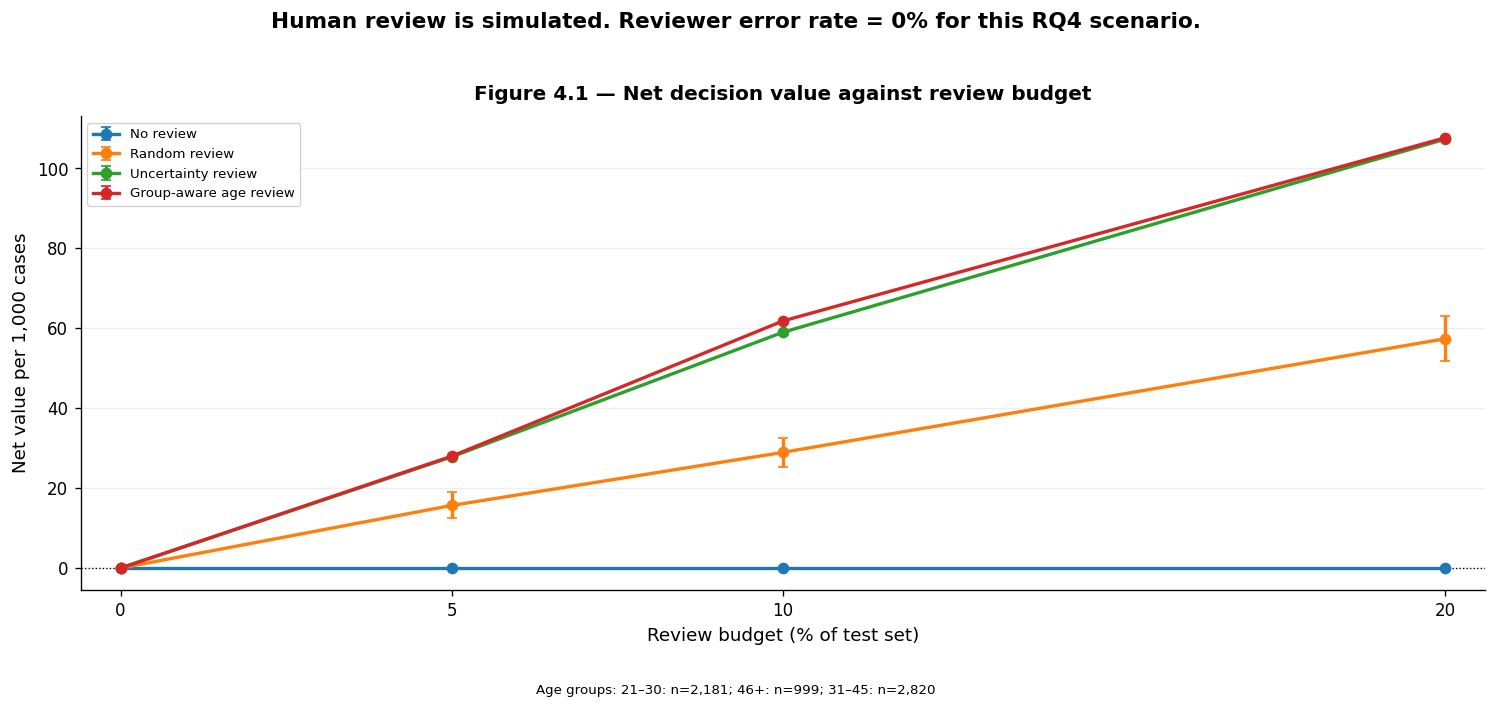

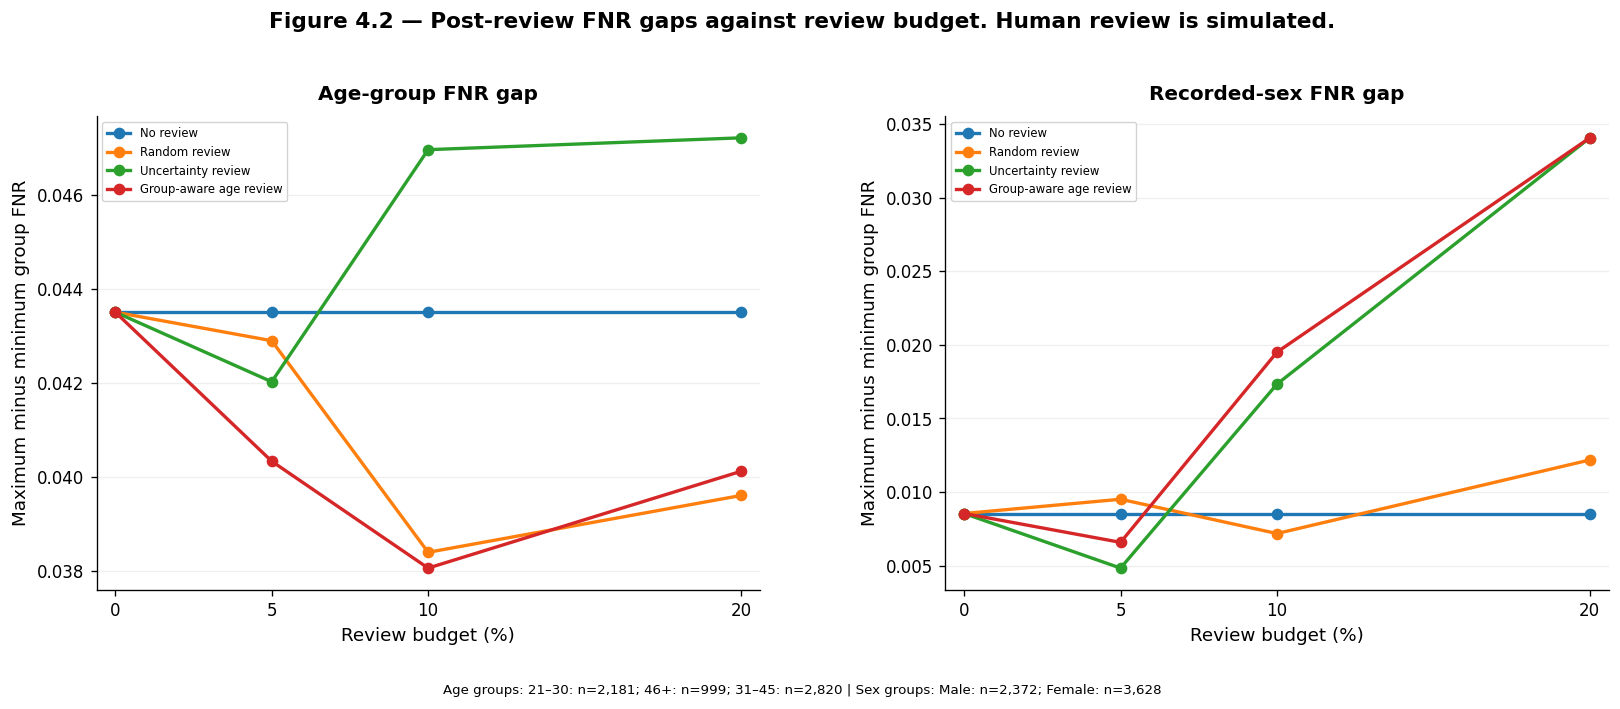

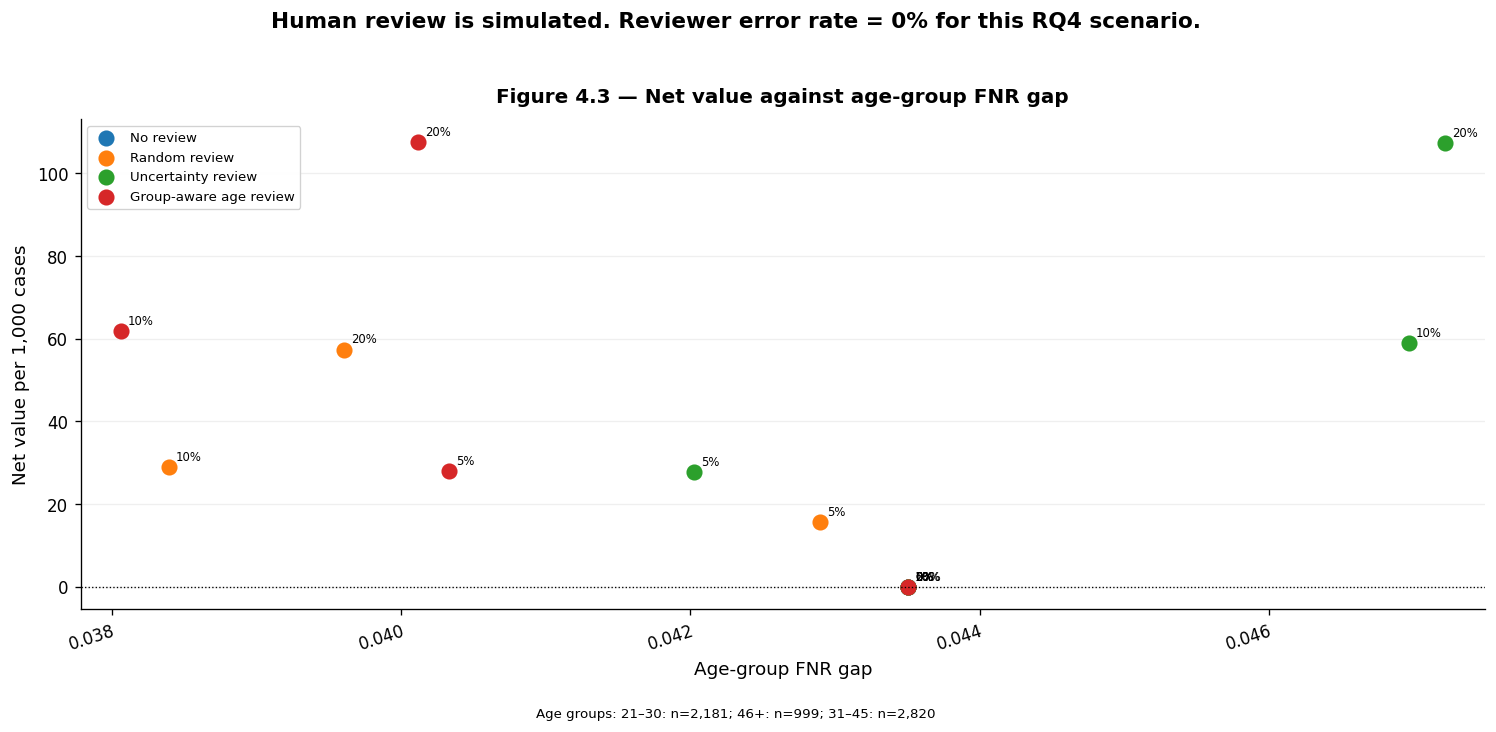

,capacity,policy,reviewer_error_rate,repetitions,bootstrap_resamples,cases_reviewed_mean,baseline_errors_corrected_mean,decision_changes_mean,errors_introduced_mean,net_value_per_1000_eligible_cases,net_value_95_percentile_low,net_value_95_percentile_high,age_FNR_gap,age_FNR_gap_95_percentile_low,age_FNR_gap_95_percentile_high,age_group_counts
0,0.05,No review,0.0,1,500,0.0,0.00,0.00,0.0,0.000000,0.000000,0.000000,0.043508,0.011331,0.106431,"21–30: n=2,181; 46+: n=999; 31–45: n=2,820"
1,0.05,Random review,0.0,20,500,300.0,101.45,101.45,0.0,15.675000,12.575000,16.568333,0.042900,0.013607,0.102836,"21–30: n=2,181; 46+: n=999; 31–45: n=2,820"
2,0.05,Uncertainty review,0.0,1,500,300.0,138.00,138.00,0.0,27.833333,21.825000,37.929167,0.042026,0.012966,0.098921,"21–30: n=2,181; 46+: n=999; 31–45: n=2,820"
3,0.05,Group-aware age review,0.0,1,500,300.0,135.00,135.00,0.0,28.000000,20.666667,37.333333,0.040334,0.012549,0.099236,"21–30: n=2,181; 46+: n=999; 31–45: n=2,820"
4,0.10,No review,0.0,1,500,0.0,0.00,0.00,0.0,0.000000,0.000000,0.000000,0.043508,0.011331,0.106431,"21–30: n=2,181; 46+: n=999; 31–45: n=2,820"
5,0.10,Random review,0.0,20,500,600.0,200.10,200.10,0.0,28.950000,25.360000,32.433333,0.038394,0.015584,0.096413,"21–30: n=2,181; 46+: n=999; 31–45: n=2,820"
6,0.10,Uncertainty review,0.0,1,500,600.0,280.00,280.00,0.0,59.000000,48.991667,71.087500,0.046968,0.014269,0.096427,"21–30: n=2,181; 46+: n=999; 31–45: n=2,820"
7,0.10,Group-aware age review,0.0,1,500,600.0,285.00,285.00,0.0,61.833333,50.641667,73.841667,0.038058,0.009534,0.092700,"21–30: n=2,181; 46+: n=999; 31–45: n=2,820"
8,0.20,No review,0.0,1,500,0.0,0.00,0.00,0.0,0.000000,0.000000,0.000000,0.043508,0.011331,0.106431,"21–30: n=2,181; 46+: n=999; 31–45: n=2,820"
9,0.20,Random review,0.0,20,500,1200.0,394.90,394.90,0.0,57.383333,52.219583,64.061250,0.039604,0.017875,0.087480,"21–30: n=2,181; 46+: n=999; 31–45: n=2,820"


,capacity,matched_review_count,comparison,paired_bootstrap_resamples,paired_net_value_difference_mean,paired_net_value_95_percentile_low,paired_net_value_95_percentile_high,paired_age_FNR_gap_difference_mean,paired_age_FNR_gap_95_percentile_low,paired_age_FNR_gap_95_percentile_high
0,0.05,300,Group-aware age review minus Uncertainty review,500,-1.035333,-5.000000,2.254167,0.000307,-0.012786,0.015352
1,0.10,600,Group-aware age review minus Uncertainty review,500,1.904667,-1.833333,7.000000,-0.006338,-0.020780,0.005161
2,0.20,1200,Group-aware age review minus Uncertainty review,500,0.136000,-3.587500,4.166667,-0.007266,-0.025044,0.004219


In [15]:
age_count_caption = group_count_text(TEST_AGE_GROUPS)
sex_count_caption = group_count_text(TEST_SEX_GROUPS)

# Figure 4.1: net value against review budget.
fig, ax = plt.subplots(figsize=(9, 5.5))
for policy in POLICIES:
    frame = rq4_curve[rq4_curve['policy'] == policy].sort_values('capacity')
    ax.errorbar(frame['capacity'] * 100, frame['net_value_per_1000'],
                yerr=frame['net_value_per_1000_sd'], marker='o', capsize=3,
                linewidth=2, label=policy)
ax.axhline(0, color='black', linewidth=0.8, linestyle=':')
ax.set(title='Figure 4.1 — Net decision value against review budget',
       xlabel='Review budget (% of test set)', ylabel='Net value per 1,000 cases')
ax.set_xticks([0, 5, 10, 20])
ax.legend(frameon=False, fontsize=8)
clean_axis(ax)
fig.suptitle('Human review is simulated. Reviewer error rate = 0% for this RQ4 scenario.',
             fontsize=10, fontweight='bold')
fig.text(0.5, 0.01, 'Age groups: ' + age_count_caption, ha='center', fontsize=8)
fig.tight_layout(rect=[0, 0.05, 1, 0.92])
save_figure('Figure_4.1_net_value_by_budget', fig)

# Figure 4.2: post-review FNR gaps against review budget.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, metric, title in [
    (axes[0], 'age_FNR_gap', 'Age-group FNR gap'),
    (axes[1], 'sex_FNR_gap', 'Recorded-sex FNR gap')
]:
    for policy in POLICIES:
        frame = rq4_curve[rq4_curve['policy'] == policy].sort_values('capacity')
        ax.plot(frame['capacity'] * 100, frame[metric], marker='o', linewidth=2, label=policy)
    ax.set(title=title, xlabel='Review budget (%)', ylabel='Maximum minus minimum group FNR')
    ax.set_xticks([0, 5, 10, 20])
    ax.legend(frameon=False, fontsize=7)
    clean_axis(ax)
fig.suptitle('Figure 4.2 — Post-review FNR gaps against review budget. Human review is simulated.',
             fontsize=12, fontweight='bold')
fig.text(0.5, 0.01, 'Age groups: ' + age_count_caption + ' | Sex groups: ' + sex_count_caption,
         ha='center', fontsize=8)
fig.tight_layout(rect=[0, 0.06, 1, 0.92])
save_figure('Figure_4.2_FNR_gap_by_budget', fig)

# Figure 4.3: net value against age FNR gap.
fig, ax = plt.subplots(figsize=(9, 6))
for policy in POLICIES:
    frame = rq4_curve[rq4_curve['policy'] == policy]
    ax.scatter(frame['age_FNR_gap'], frame['net_value_per_1000'], s=75, label=policy)
    for row in frame.itertuples():
        ax.annotate(f'{row.capacity:.0%}', (row.age_FNR_gap, row.net_value_per_1000),
                    xytext=(4, 4), textcoords='offset points', fontsize=7)
ax.axhline(0, color='black', linewidth=0.8, linestyle=':')
ax.set(title='Figure 4.3 — Net value against age-group FNR gap',
       xlabel='Age-group FNR gap', ylabel='Net value per 1,000 cases')
ax.legend(frameon=False, fontsize=8)
clean_axis(ax)
fig.suptitle('Human review is simulated. Reviewer error rate = 0% for this RQ4 scenario.',
             fontsize=10, fontweight='bold')
fig.text(0.5, 0.01, 'Age groups: ' + age_count_caption, ha='center', fontsize=8)
fig.tight_layout(rect=[0, 0.05, 1, 0.92])
save_figure('Figure_4.3_value_vs_age_FNR_gap', fig)

# RQ4: one common set of 500 test-set bootstrap indices for every policy and budget.
# Rebuild all queues in each bootstrap sample; round each k using Python round.
# Allocate age-aware quotas by largest-remainder proportional rounding; stable age-group tie order.
# Random case selection and reviewer errors use separate RNG seed namespaces.
# The main RQ4 0%-error reviewer is deterministic; 20 stochastic repeats apply to random policy.
BOOTSTRAP_SEED = SEED + 700000
boot_rng = np.random.default_rng(BOOTSTRAP_SEED)
BOOT_INDICES = [boot_rng.integers(0, len(y_test), len(y_test)) for _ in range(BOOTSTRAP_RESAMPLES)]

def percentile_interval(values):
    a = np.asarray(values, dtype=float)
    valid = a[np.isfinite(a)]
    return (float(np.quantile(valid,.025)),float(np.quantile(valid,.975))) if len(valid) else (np.nan,np.nan)

def rq4_bootstrap():
    base_y = np.asarray(y_test).astype(int)
    base_p = np.asarray(PRIMARY_PROBS,dtype=float)
    base_age = np.asarray(TEST_AGE_GROUPS)
    base_sex = np.asarray(TEST_SEX_GROUPS)
    rows=[]
    for b,ids in enumerate(BOOT_INDICES):
        yy,pp,aa,ss = base_y[ids],base_p[ids],base_age[ids],base_sex[ids]
        auto = (pp >= DECISION_THRESHOLD).astype(int)
        baseline_loss = float((5*((yy==1)&(auto==0)) + ((yy==0)&(auto==1))).sum())
        # Per-group positive positions cached once per resample; no pandas in inner loop.
        positive_group_masks = [(aa==label)&(yy==1) for label in np.unique(aa)]
        for cap in [0.05,0.10,0.20]:
            k = int(round(cap*len(yy)))
            for pol in POLICIES:
                net_samples=[];gap_samples=[];corrected_samples=[]
                reps = REVIEW_REPEATS if pol == 'Random review' else 1
                for rep in range(reps):
                    # Same bootstrap indices, same capacity, independently re-built policy queues.
                    selection_seed = SEED + 8000000 + b*10000 + int(cap*100)*100 + rep
                    reviewer_seed = SEED + 9000000 + b*10000 + int(cap*100)*100 + rep
                    flags=select_policy(pol,pp,k,age_groups=aa,seed=selection_seed)
                    assert flags.sum()==(0 if pol=='No review' else k)
                    # Ideal reviewer: reviewed decisions become recorded labels exactly.
                    final = np.where(flags, yy, auto)
                    loss = float((5*((yy==1)&(final==0)) + ((yy==0)&(final==1))).sum())
                    net_samples.append((baseline_loss-loss-REVIEW_COST_PER_CASE*int(flags.sum()))/len(yy)*1000)
                    positive_fnr = [float(np.mean(final[gm]==0)) for gm in positive_group_masks if gm.any()]
                    gap_samples.append(max(positive_fnr)-min(positive_fnr) if len(positive_fnr)>=2 else np.nan)
                    corrected_samples.append(int(np.sum(flags & (auto!=yy))))
                rows.append({'bootstrap':b,'capacity':cap,'policy':pol,'net_value_per_1000':float(np.mean(net_samples)),
                             'age_FNR_gap':float(np.nanmean(gap_samples)) if np.isfinite(gap_samples).any() else np.nan,
                             'baseline_errors_corrected':float(np.mean(corrected_samples))})
    return pd.DataFrame(rows)

rq4_boot = rq4_bootstrap()
headline_rows=[]
for cap in [0.05,0.10,0.20]:
    for pol in POLICIES:
        point=rq4_curve[(rq4_curve.capacity==cap)&(rq4_curve.policy==pol)].iloc[0]
        bframe=rq4_boot[(rq4_boot.capacity==cap)&(rq4_boot.policy==pol)]
        vl,vh=percentile_interval(bframe.net_value_per_1000)
        gl,gh=percentile_interval(bframe.age_FNR_gap)
        headline_rows.append({'capacity':cap,'policy':pol,'reviewer_error_rate':0.0,
            'repetitions':REVIEW_REPEATS if pol=='Random review' else 1,'bootstrap_resamples':BOOTSTRAP_RESAMPLES,
            'cases_reviewed_mean':point['n_reviewed'],'baseline_errors_corrected_mean':point['baseline_errors_corrected'],
            'decision_changes_mean':point['n_decision_changes'],'errors_introduced_mean':point['errors_introduced'],
            'net_value_per_1000_eligible_cases':point['net_value_per_1000'],
            'net_value_95_percentile_low':vl,'net_value_95_percentile_high':vh,
            'age_FNR_gap':point['age_FNR_gap'],
            'age_FNR_gap_95_percentile_low':gl,'age_FNR_gap_95_percentile_high':gh,
            'age_group_counts':group_count_text(TEST_AGE_GROUPS)})
rq4_reviews_corrections=pd.DataFrame(headline_rows)
display_and_save('Table_4.4_reviews_and_corrections',rq4_reviews_corrections)

# *Paired*, not marginal, bootstrap intervals for age-aware minus uncertainty.
paired_rows=[]
for cap in [0.05,0.10,0.20]:
    sub=rq4_boot[rq4_boot.capacity==cap]
    wide=sub.pivot(index='bootstrap',columns='policy',values=['net_value_per_1000','age_FNR_gap'])
    delta_net=wide[('net_value_per_1000','Group-aware age review')]-wide[('net_value_per_1000','Uncertainty review')]
    delta_gap=wide[('age_FNR_gap','Group-aware age review')]-wide[('age_FNR_gap','Uncertainty review')]
    nvlo,nvhi=percentile_interval(delta_net);glo,ghi=percentile_interval(delta_gap)
    paired_rows.append({'capacity':cap,'matched_review_count':int(round(cap*len(y_test))),
       'comparison':'Group-aware age review minus Uncertainty review',
       'paired_bootstrap_resamples':len(wide),'paired_net_value_difference_mean':float(delta_net.mean()),
       'paired_net_value_95_percentile_low':nvlo,'paired_net_value_95_percentile_high':nvhi,
       'paired_age_FNR_gap_difference_mean':float(delta_gap.mean()),
       'paired_age_FNR_gap_95_percentile_low':glo,'paired_age_FNR_gap_95_percentile_high':ghi})
rq4_paired=pd.DataFrame(paired_rows)
display_and_save('Extra_Table_4.5_paired_policy_differences',rq4_paired)


## 13. RQ5 — Reviewer-error sensitivity

**Research question:** How robust are the review policies when human reviewers make mistakes?

**Purpose:** Use reviewer error rates of 0%, 10%, 20%, 30% and 40%. Use the same error rate for both classes. Each reviewed case has an independent error draw. The reviewer sees the true label inside the simulation. The review decision replaces the automatic decision. Use 20 repetitions for every policy, budget and error-rate cell. Use the four review budgets from RQ4.


In [16]:
rq5_replicate_rows = []
for capacity_index, capacity in enumerate(CAPACITY_LEVELS):
    queue_size = int(round(capacity * len(y_test)))
    for error_index, error_rate in enumerate(REVIEWER_ERROR_RATES):
        for policy_index, policy in enumerate(POLICIES):
            for repetition in range(REVIEW_REPEATS):
                cell_seed = (SEED + 1000000 + capacity_index * 100000 +
                             error_index * 10000 + policy_index * 1000 + repetition)
                reviewed = select_policy(
                    policy, PRIMARY_PROBS, queue_size,
                    age_groups=TEST_AGE_GROUPS, seed=cell_seed
                )
                metrics, _ = simulate_review(
                    y_test, PRIMARY_PROBS, reviewed,
                    reviewer_error_rate=error_rate,
                    seed=cell_seed + 5000000,
                    sex_groups=TEST_SEX_GROUPS,
                    age_groups=TEST_AGE_GROUPS
                )
                rq5_replicate_rows.append({
                    'capacity': capacity,
                    'reviewer_error_rate': error_rate,
                    'policy': policy,
                    'repetition': repetition + 1,
                    **metrics
                })

rq5_replicates = pd.DataFrame(rq5_replicate_rows)
rq5_group_keys = ['capacity', 'reviewer_error_rate', 'policy']
rq5_mean = rq5_replicates.groupby(rq5_group_keys, as_index=False).mean(numeric_only=True)
rq5_sd = (rq5_replicates.groupby(rq5_group_keys)[
    ['net_value_per_1000', 'age_FNR_gap', 'sex_FNR_gap']
].std(ddof=1).add_suffix('_sd').reset_index())
rq5_grid = rq5_mean.merge(rq5_sd, on=rq5_group_keys, how='left')
rq5_grid['repetitions'] = REVIEW_REPEATS
rq5_grid = rq5_grid.drop(columns=['repetition'])
rq5_grid = rq5_grid.rename(columns={
    'n_reviewed': 'n_reviewed_mean',
    'n_decision_changes': 'decision_changes_mean',
    'baseline_errors_corrected': 'corrections_mean',
    'errors_introduced': 'errors_introduced_mean',
    'net_value_per_1000': 'net_value_per_1000_mean',
    'age_FNR_gap': 'age_FNR_gap_mean',
    'sex_FNR_gap': 'sex_FNR_gap_mean',
    'age_review_rate_gap': 'age_review_rate_gap_mean',
    'sex_review_rate_gap': 'sex_review_rate_gap_mean',
})

# RQ5 semantics: a changed decision may fix an old error or introduce a new one.
assert np.allclose(
    rq5_grid['decision_changes_mean'],
    rq5_grid['corrections_mean'] + rq5_grid['errors_introduced_mean'],
    rtol=1e-9, atol=1e-9,
)
display_and_save('Extra_Table_RQ5_review_simulation_grid', rq5_grid)


,capacity,reviewer_error_rate,policy,n_reviewed_mean,review_rate,baseline_weighted_loss,final_weighted_loss,review_cost_total,total_cost_including_review,net_value_per_1000_mean,...,age_FNR_gap_mean,age_FPR_gap,age_review_rate_gap_mean,sex_FNR_gap_mean,sex_FPR_gap,sex_review_rate_gap_mean,net_value_per_1000_sd,age_FNR_gap_sd,sex_FNR_gap_sd,repetitions
0,0.0,0.0,Group-aware age review,0.0,0.0,3239.0,3239.00,0.0,3239.00,0.000000,...,0.043508,0.061283,0.000000,0.008542,0.013592,0.000000,0.000000,0.000000,0.000000,20
1,0.0,0.0,No review,0.0,0.0,3239.0,3239.00,0.0,3239.00,0.000000,...,0.043508,0.061283,0.000000,0.008542,0.013592,0.000000,0.000000,0.000000,0.000000,20
2,0.0,0.0,Random review,0.0,0.0,3239.0,3239.00,0.0,3239.00,0.000000,...,0.043508,0.061283,0.000000,0.008542,0.013592,0.000000,0.000000,0.000000,0.000000,20
3,0.0,0.0,Uncertainty review,0.0,0.0,3239.0,3239.00,0.0,3239.00,0.000000,...,0.043508,0.061283,0.000000,0.008542,0.013592,0.000000,0.000000,0.000000,0.000000,20
4,0.0,0.1,Group-aware age review,0.0,0.0,3239.0,3239.00,0.0,3239.00,0.000000,...,0.043508,0.061283,0.000000,0.008542,0.013592,0.000000,0.000000,0.000000,0.000000,20
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
75,0.2,0.3,Uncertainty review,1200.0,0.2,3239.0,2879.80,300.0,3179.80,9.866667,...,0.047003,0.059242,0.022718,0.015813,0.027623,0.029004,5.590719,0.008492,0.007840,20
76,0.2,0.4,Group-aware age review,1200.0,0.2,3239.0,3079.55,300.0,3379.55,-23.425000,...,0.041268,0.060127,0.000292,0.011852,0.030832,0.031096,6.643705,0.010638,0.007719,20
77,0.2,0.4,No review,0.0,0.0,3239.0,3239.00,0.0,3239.00,0.000000,...,0.043508,0.061283,0.000000,0.008542,0.013592,0.000000,0.000000,0.000000,0.000000,20
78,0.2,0.4,Random review,1200.0,0.2,3239.0,3507.70,300.0,3807.70,-94.783333,...,0.034996,0.047071,0.017411,0.014442,0.012112,0.008869,9.252959,0.016826,0.009699,20


## 14. RQ5 — Sensitivity figures and ranks

**Purpose:** Save Figure 5.1 for net value and Figure 5.2 for age FNR gap. Show one panel for each review budget. Save Table 5.3 with the highest tested error rate that keeps net value non-negative. Do not interpolate between tested error rates. Save Table 5.4 with value and age-gap ranks. Every review figure states that human review is simulated.


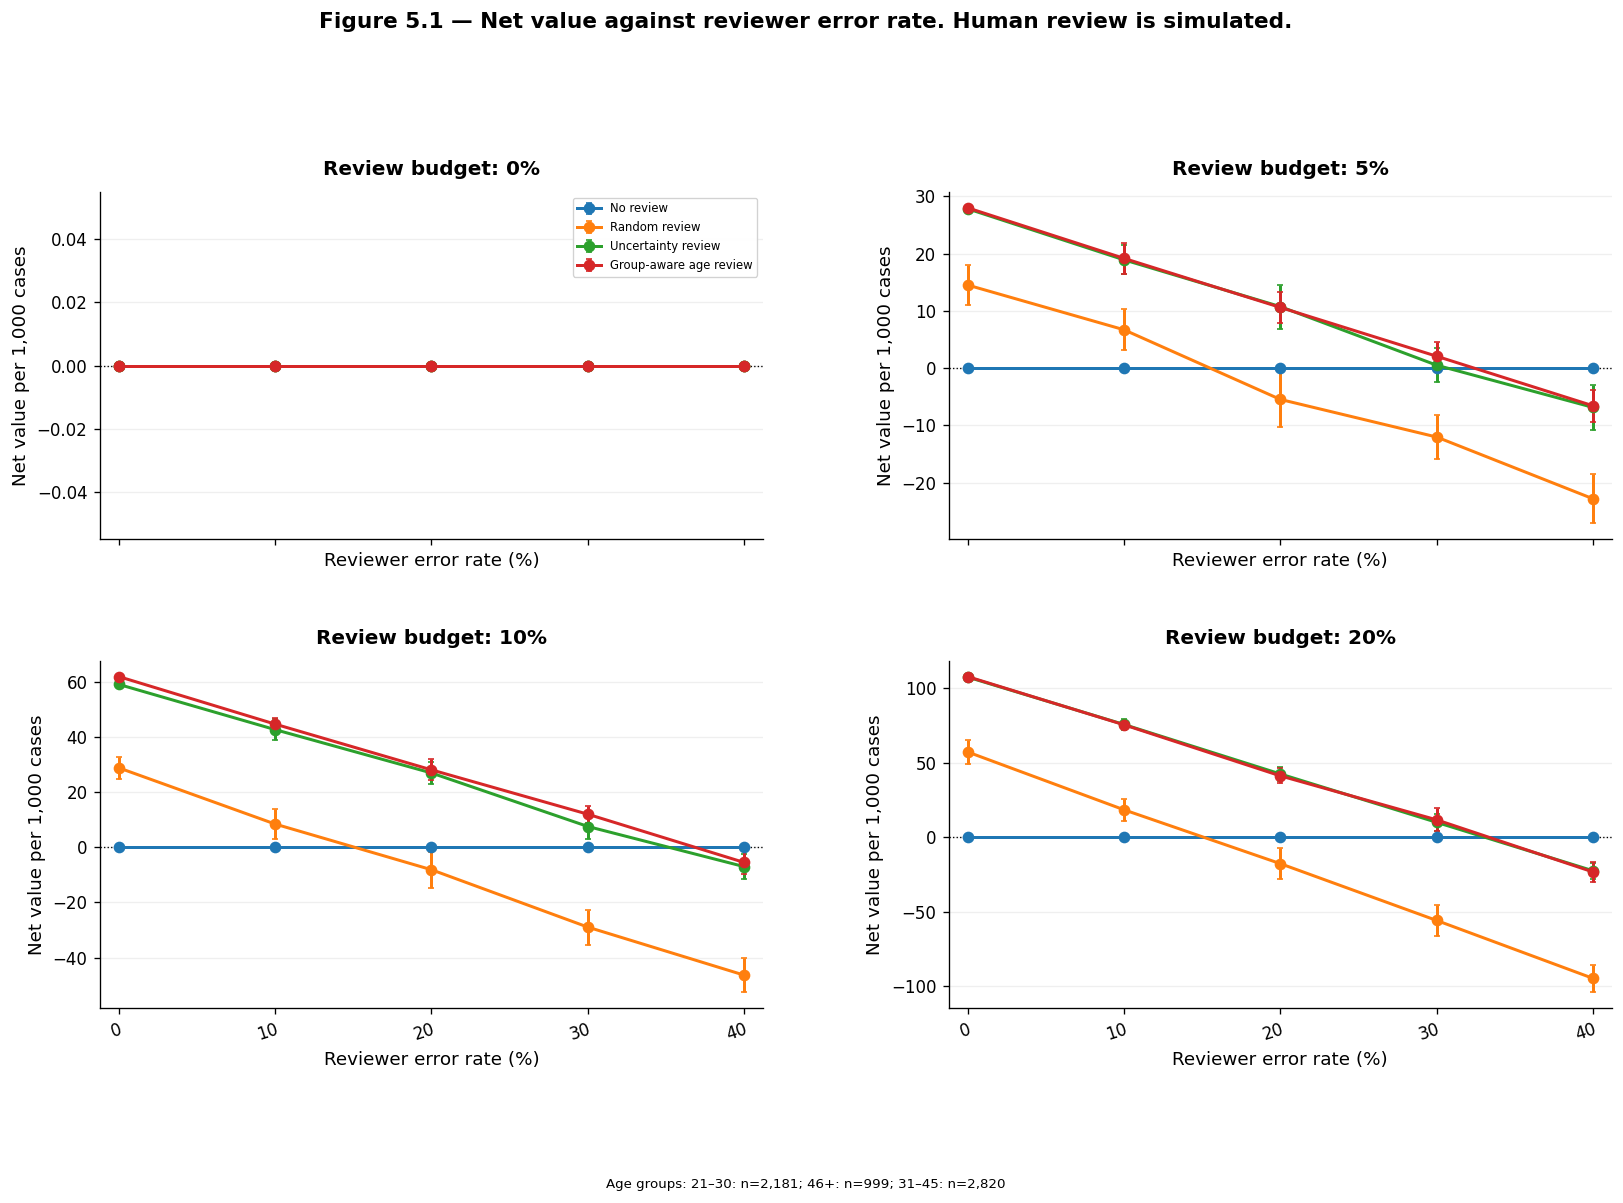

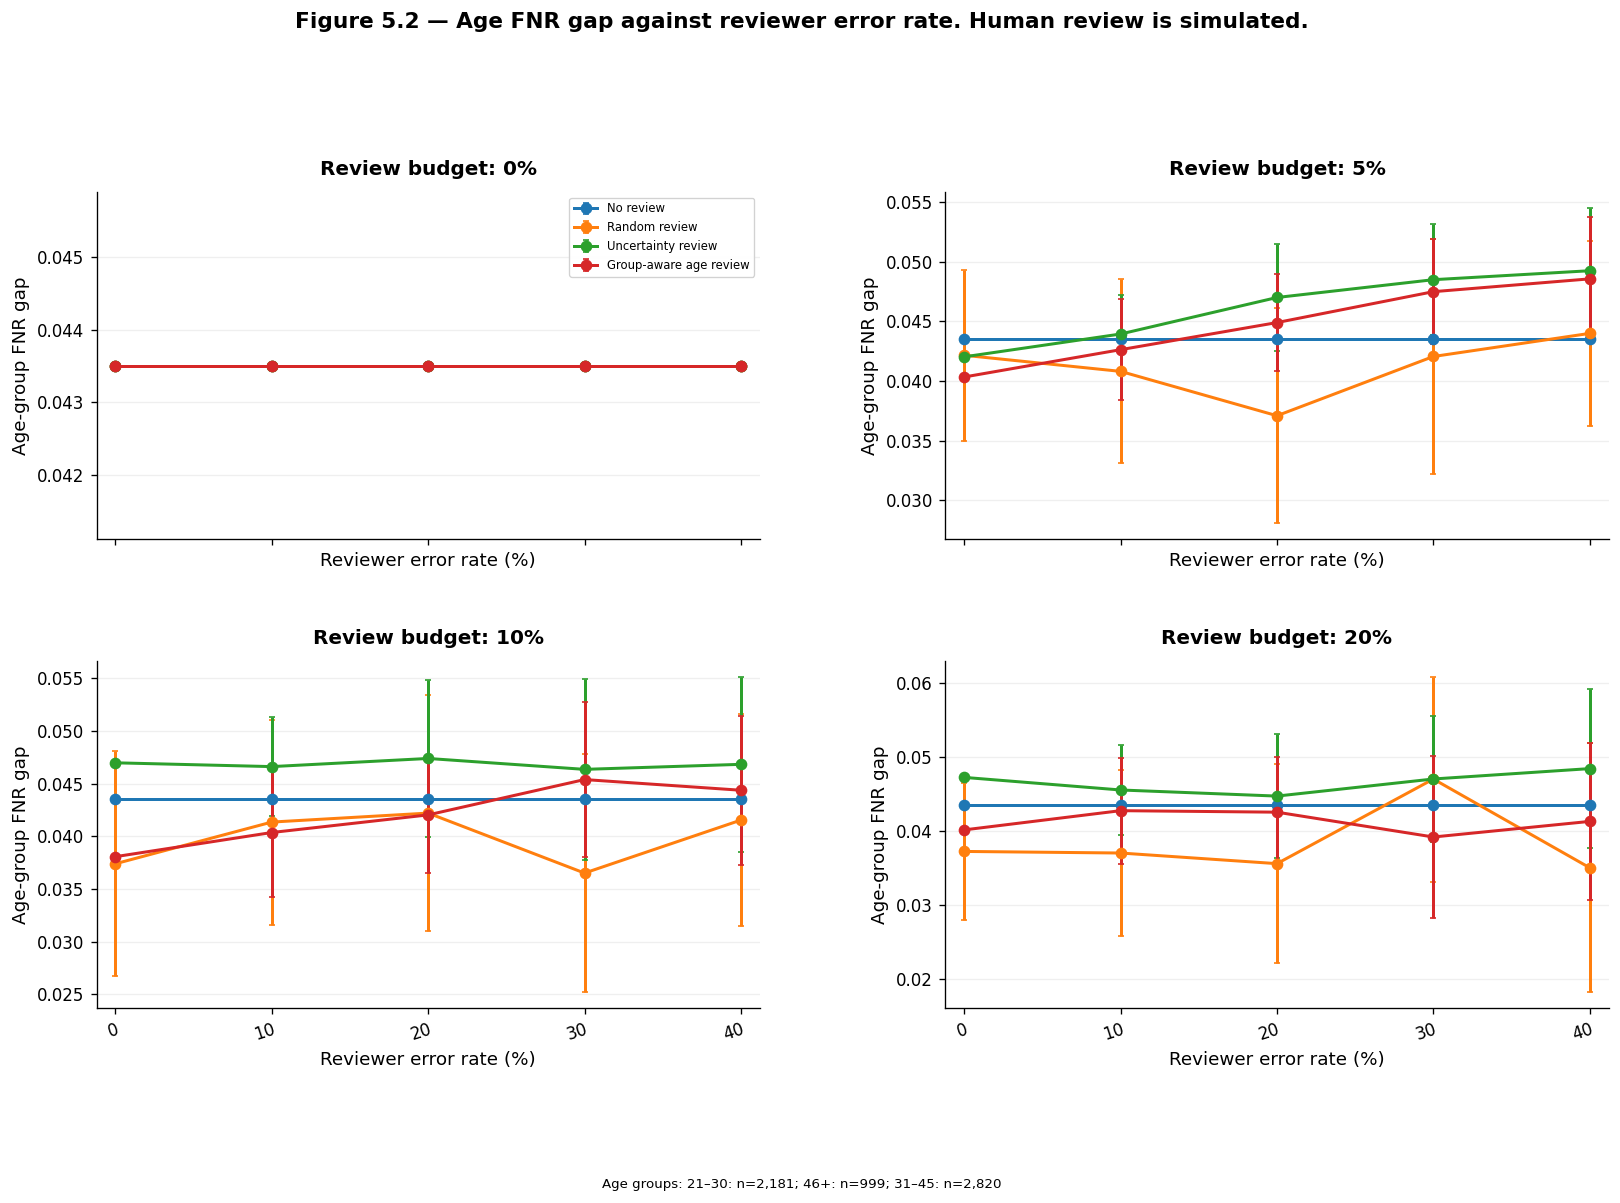

,capacity,policy,highest_tested_error_rate_with_nonnegative_value,interpolated_zero_crossing_error_rate,tested_error_rates,rule
0,0.00,Group-aware age review,NaN,Not applicable,"0%, 10%, 20%, 30%, 40%",Not applicable; no case is reviewed
1,0.00,No review,NaN,Not applicable,"0%, 10%, 20%, 30%, 40%",Not applicable; no case is reviewed
2,0.00,Random review,NaN,Not applicable,"0%, 10%, 20%, 30%, 40%",Not applicable; no case is reviewed
3,0.00,Uncertainty review,NaN,Not applicable,"0%, 10%, 20%, 30%, 40%",Not applicable; no case is reviewed
4,0.05,Group-aware age review,0.3,32.4%,"0%, 10%, 20%, 30%, 40%",Linear interpolation between adjacent tested e...
5,0.05,No review,NaN,Not applicable,"0%, 10%, 20%, 30%, 40%",Not applicable; no case is reviewed
6,0.05,Random review,0.1,15.5%,"0%, 10%, 20%, 30%, 40%",Linear interpolation between adjacent tested e...
7,0.05,Uncertainty review,0.3,30.7%,"0%, 10%, 20%, 30%, 40%",Linear interpolation between adjacent tested e...
8,0.10,Group-aware age review,0.3,36.8%,"0%, 10%, 20%, 30%, 40%",Linear interpolation between adjacent tested e...
9,0.10,No review,NaN,Not applicable,"0%, 10%, 20%, 30%, 40%",Not applicable; no case is reviewed


,capacity,reviewer_error_rate,policy,net_value_per_1000_mean,net_value_rank,age_FNR_gap_mean,age_group_counts,age_FNR_gap_rank
0,0.05,0.0,Group-aware age review,28.000000,1,0.040334,"21–30: n=2,181; 46+: n=999; 31–45: n=2,820",1
1,0.05,0.0,No review,0.000000,4,0.043508,"21–30: n=2,181; 46+: n=999; 31–45: n=2,820",4
2,0.05,0.0,Random review,14.508333,3,0.042156,"21–30: n=2,181; 46+: n=999; 31–45: n=2,820",3
3,0.05,0.0,Uncertainty review,27.833333,2,0.042026,"21–30: n=2,181; 46+: n=999; 31–45: n=2,820",2
4,0.05,0.1,Group-aware age review,19.166667,1,0.042626,"21–30: n=2,181; 46+: n=999; 31–45: n=2,820",2
5,0.05,0.1,No review,0.000000,4,0.043508,"21–30: n=2,181; 46+: n=999; 31–45: n=2,820",3
6,0.05,0.1,Random review,6.691667,3,0.040807,"21–30: n=2,181; 46+: n=999; 31–45: n=2,820",1
7,0.05,0.1,Uncertainty review,18.908333,2,0.043940,"21–30: n=2,181; 46+: n=999; 31–45: n=2,820",4
8,0.05,0.2,Group-aware age review,10.591667,2,0.044901,"21–30: n=2,181; 46+: n=999; 31–45: n=2,820",3
9,0.05,0.2,No review,0.000000,3,0.043508,"21–30: n=2,181; 46+: n=999; 31–45: n=2,820",2


In [17]:
# Figure 5.1: net value against symmetric reviewer error rate.
fig, axes = plt.subplots(2, 2, figsize=(14, 10), sharex=True)
for ax, capacity in zip(axes.ravel(), CAPACITY_LEVELS):
    frame_capacity = rq5_grid[rq5_grid['capacity'] == capacity]
    for policy in POLICIES:
        frame = frame_capacity[frame_capacity['policy'] == policy].sort_values('reviewer_error_rate')
        ax.errorbar(frame['reviewer_error_rate'] * 100,
                    frame['net_value_per_1000_mean'],
                    yerr=frame['net_value_per_1000_sd'],
                    marker='o', capsize=2, linewidth=1.8, label=policy)
    ax.axhline(0, color='black', linewidth=0.8, linestyle=':')
    ax.set(title=f'Review budget: {capacity:.0%}',
           xlabel='Reviewer error rate (%)', ylabel='Net value per 1,000 cases')
    ax.set_xticks([0, 10, 20, 30, 40])
    clean_axis(ax)
axes[0, 0].legend(frameon=False, fontsize=7)
fig.suptitle('Figure 5.1 — Net value against reviewer error rate. Human review is simulated.',
             fontsize=13, fontweight='bold')
fig.text(0.5, 0.01, 'Age groups: ' + group_count_text(TEST_AGE_GROUPS),
         ha='center', fontsize=8)
fig.tight_layout(rect=[0, 0.04, 1, 0.94])
save_figure('Figure_5.1_net_value_by_reviewer_error', fig)

# Figure 5.2: age FNR gap against symmetric reviewer error rate.
fig, axes = plt.subplots(2, 2, figsize=(14, 10), sharex=True)
for ax, capacity in zip(axes.ravel(), CAPACITY_LEVELS):
    frame_capacity = rq5_grid[rq5_grid['capacity'] == capacity]
    for policy in POLICIES:
        frame = frame_capacity[frame_capacity['policy'] == policy].sort_values('reviewer_error_rate')
        ax.errorbar(frame['reviewer_error_rate'] * 100,
                    frame['age_FNR_gap_mean'],
                    yerr=frame['age_FNR_gap_sd'],
                    marker='o', capsize=2, linewidth=1.8, label=policy)
    ax.set(title=f'Review budget: {capacity:.0%}',
           xlabel='Reviewer error rate (%)', ylabel='Age-group FNR gap')
    ax.set_xticks([0, 10, 20, 30, 40])
    clean_axis(ax)
axes[0, 0].legend(frameon=False, fontsize=7)
fig.suptitle('Figure 5.2 — Age FNR gap against reviewer error rate. Human review is simulated.',
             fontsize=13, fontweight='bold')
fig.text(0.5, 0.01, 'Age groups: ' + group_count_text(TEST_AGE_GROUPS),
         ha='center', fontsize=8)
fig.tight_layout(rect=[0, 0.04, 1, 0.94])
save_figure('Figure_5.2_age_FNR_gap_by_reviewer_error', fig)

# Table 5.3: report the highest tested nonnegative rate and linearly interpolate the zero crossing.
break_even_rows = []
for (capacity, policy), frame in rq5_grid.groupby(['capacity', 'policy'], sort=False):
    frame = frame.sort_values('reviewer_error_rate')
    eligible = frame.loc[
        frame['net_value_per_1000_mean'] >= 0, 'reviewer_error_rate'
    ]
    if capacity == 0 or policy == 'No review':
        highest_tested = np.nan
        crossing = 'Not applicable'
        break_even_rule = 'Not applicable; no case is reviewed'
    else:
        highest_tested = float(eligible.max()) if not eligible.empty else np.nan
        rates = frame['reviewer_error_rate'].to_numpy(dtype=float)
        values = frame['net_value_per_1000_mean'].to_numpy(dtype=float)
        crossing = None
        if values[-1] > 0:
            crossing = 'above 40%'
        else:
            for index in range(len(rates) - 1):
                left_value = values[index]
                right_value = values[index + 1]
                if left_value == 0:
                    crossing = f'{rates[index]:.1%}'
                    break
                if left_value * right_value < 0 or right_value == 0:
                    if right_value == left_value:
                        crossing_rate = rates[index + 1]
                    else:
                        crossing_rate = rates[index] + (
                            (0.0 - left_value) * (rates[index + 1] - rates[index]) /
                            (right_value - left_value)
                        )
                    crossing = f'{crossing_rate:.1%}'
                    break
        if crossing is None:
            crossing = 'at or below 0%'
        break_even_rule = 'Linear interpolation between adjacent tested error rates'
    break_even_rows.append({
        'capacity': capacity,
        'policy': policy,
        'highest_tested_error_rate_with_nonnegative_value': highest_tested,
        'interpolated_zero_crossing_error_rate': crossing,
        'tested_error_rates': ', '.join(f'{v:.0%}' for v in REVIEWER_ERROR_RATES),
        'rule': break_even_rule
    })
rq5_break_even = pd.DataFrame(break_even_rows)
display_and_save('Table_5.3_break_even_reviewer_error_rate', rq5_break_even)

# Table 5.4: rank policies by net value and age FNR gap. Omit 0% budget because all policies tie.
rank_rows = []
for (capacity, error_rate), frame in rq5_grid.groupby(['capacity', 'reviewer_error_rate'], sort=False):
    if capacity == 0:
        continue
    ranked = frame.copy()
    ranked['net_value_rank'] = ranked['net_value_per_1000_mean'].rank(
        ascending=False, method='min'
    ).astype(int)
    ranked['age_FNR_gap_rank'] = ranked['age_FNR_gap_mean'].rank(
        ascending=True, method='min'
    ).astype(int)
    for row in ranked.itertuples():
        rank_rows.append({
            'capacity': capacity,
            'reviewer_error_rate': error_rate,
            'policy': row.policy,
            'net_value_per_1000_mean': row.net_value_per_1000_mean,
            'net_value_rank': row.net_value_rank,
            'age_FNR_gap_mean': row.age_FNR_gap_mean,
            'age_group_counts': group_count_text(TEST_AGE_GROUPS),
            'age_FNR_gap_rank': row.age_FNR_gap_rank
        })
rq5_policy_ranks = pd.DataFrame(rank_rows)
display_and_save('Table_5.4_policy_ranks', rq5_policy_ranks)


## Supplementary analyses

The next cells report supporting cohort summaries and the separate German Credit benchmark. These results are not part of Tables 1.1–5.4. The German audit covers age only. The source `personal_status_sex` field mixes sex and marital status. It does not support a clean sex-only audit.


In [18]:
GERMAN_TARGET='default_bad_risk'
german_feature_cols=[c for c in GERMAN_COLUMNS[:-1] if c not in ['risk']]
german_cat_cols=[c for c in german_feature_cols if c not in GERMAN_NUMERIC]
Xg=german_df[german_feature_cols].copy(); yg=german_df[GERMAN_TARGET].astype(int).copy()
idxg=np.arange(len(german_df))
idxg_train,idxg_temp=train_test_split(idxg,test_size=.40,random_state=SEED,stratify=yg)
idxg_val,idxg_test=train_test_split(idxg_temp,test_size=.50,random_state=SEED,stratify=yg.iloc[idxg_temp])
Xg_train,yg_train=Xg.iloc[idxg_train],yg.iloc[idxg_train]
Xg_val,yg_val=Xg.iloc[idxg_val],yg.iloc[idxg_val]
Xg_test,yg_test=Xg.iloc[idxg_test],yg.iloc[idxg_test]
german_test_audit=german_df.iloc[idxg_test].reset_index(drop=True)

print('German train/validation/test:',len(idxg_train),len(idxg_val),len(idxg_test))
print('German positive event = source class 2 (bad risk). Positive share:',f'{yg.mean():.3%}')
print('German sex audit: not reported. personal_status_sex combines sex and marital status.')
print('German records below age 21 are outside the three specified age groups:', int((german_df['age'] < 21).sum()))


German train/validation/test: 600 200 200
German positive event = source class 2 (bad risk). Positive share: 30.000%
German sex audit: not reported. personal_status_sex combines sex and marital status.
German records below age 21 are outside the three specified age groups: 16


### German Credit — Models and age audit

**Purpose:** Fit both model families on the German benchmark. Calibrate with validation data only. Report the German model metrics and an age-only audit. Do not report a German sex audit because the source field combines sex and marital status. Report the sample count for each age group.


In [19]:
german_models = {}
german_metric_rows = []
for name in MODEL_NAMES:
    print('Fitting German benchmark:', name)
    result = fit_with_validation_calibration(
        name, Xg_train, yg_train, Xg_val, yg_val, Xg_test,
        categorical_cols=german_cat_cols
    )
    german_models[name] = result
    for kind, key in [('Raw', 'p_test_raw'), ('Validation calibrated', 'p_test_cal')]:
        metrics = classification_metrics(yg_test, result[key])
        predictions = (result[key] >= DECISION_THRESHOLD).astype(int)
        tn, fp, fn, tp = confusion_matrix(yg_test, predictions, labels=[0, 1]).ravel()
        weighted_loss = (FALSE_POSITIVE_COST * fp + FALSE_NEGATIVE_COST * fn) / len(yg_test)
        german_metric_rows.append({
            'model': name,
            'probability_version': kind,
            **metrics,
            'scenario_weighted_loss_per_case': weighted_loss
        })
german_benchmark_metrics = pd.DataFrame(german_metric_rows)
display_and_save('Extra_Table_German_benchmark_metrics', german_benchmark_metrics)

# Select a German model using validation AUROC only.
german_validation_auc = {
    name: roc_auc_score(yg_val, result['p_val_cal'])
    for name, result in german_models.items()
}
GERMAN_PRIMARY_NAME = max(MODEL_NAMES, key=lambda model: (german_validation_auc[model], -MODEL_NAMES.index(model)))
GERMAN_PRIMARY_PROBS = german_models[GERMAN_PRIMARY_NAME]['p_test_cal']

# Audit only the three requested age groups. Exclude records below age 21.
german_age_mask = german_test_audit['age'].to_numpy() >= 21
german_age_audit = group_audit(
    yg_test.to_numpy()[german_age_mask],
    np.asarray(GERMAN_PRIMARY_PROBS)[german_age_mask],
    german_test_audit.loc[german_age_mask, 'age_group'].reset_index(drop=True),
    'Age group'
)
display_and_save('Extra_Table_German_age_audit', german_age_audit)
print('German model selected on validation AUROC:', GERMAN_PRIMARY_NAME)
print('German validation AUROC:', {k: round(v, 4) for k, v in german_validation_auc.items()})
print('German age group sample counts:', group_count_text(german_test_audit.loc[german_age_mask, 'age_group']))
print('German records below age 21 excluded from the age audit:', int((~german_age_mask).sum()))

selection_german = pd.DataFrame([{'dataset':'Statlog German Credit','model':name,'validation_calibrated_AUROC':german_validation_auc[name], 'selected':name==GERMAN_PRIMARY_NAME,'tie_rule':MODEL_TIE_RULE} for name in MODEL_NAMES])
display_and_save('Extra_Table_German_model_selection', selection_german)


Fitting German benchmark: Logistic Regression
Fitting German benchmark: Gradient Boosting


,model,probability_version,n,threshold,AUROC,Average precision,Brier score,Log loss,ECE (10 bins),Accuracy,Precision,Recall / sensitivity,Specificity,FPR,FNR,F1,scenario_weighted_loss_per_case
0,Logistic Regression,Raw,200,0.166667,0.791310,0.632566,0.164790,0.494195,0.072491,0.645,0.452991,0.883333,0.542857,0.457143,0.116667,0.598870,0.495
1,Logistic Regression,Validation calibrated,200,0.166667,0.791310,0.632566,0.163645,0.491181,0.060100,0.645,0.452991,0.883333,0.542857,0.457143,0.116667,0.598870,0.495
2,Gradient Boosting,Raw,200,0.166667,0.757976,0.546522,0.177961,0.522542,0.066206,0.610,0.428571,0.900000,0.485714,0.514286,0.100000,0.580645,0.510
3,Gradient Boosting,Validation calibrated,200,0.166667,0.757976,0.546522,0.180221,0.527156,0.074206,0.645,0.453782,0.900000,0.535714,0.464286,0.100000,0.603352,0.475


,grouping,group,n,n_positive,n_negative,positive_label_rate,mean_predicted_probability,Brier score,ECE (10 bins),FPR,FNR,precision,positive_prediction_rate,reviewed_n,review_rate,share_of_all_reviews
0,Age group,21–30,84,32,52,0.380952,0.393058,0.218292,0.099666,0.711538,0.156250,0.421875,0.761905,0,0.0,0.0
1,Age group,46+,36,7,29,0.194444,0.200827,0.136850,0.122887,0.241379,0.142857,0.461538,0.361111,0,0.0,0.0
2,Age group,31–45,77,19,58,0.246753,0.250662,0.153999,0.142515,0.344828,0.000000,0.487179,0.506494,0,0.0,0.0


German model selected on validation AUROC: Gradient Boosting
German validation AUROC: {'Logistic Regression': 0.8076, 'Gradient Boosting': 0.8096}
German age group sample counts: 21–30: n=84; 46+: n=36; 31–45: n=77
German records below age 21 excluded from the age audit: 3


,dataset,model,validation_calibrated_AUROC,selected,tie_rule
0,Statlog German Credit,Logistic Regression,0.807619,False,Higher calibrated validation AUROC; exact tie ...
1,Statlog German Credit,Gradient Boosting,0.809643,True,Higher calibrated validation AUROC; exact tie ...


### German Credit — Review simulation

**Purpose:** Repeat the RQ4 policy comparison on the German Credit test cases. The best German model is selected by validation AUROC. The simulation uses the same four policies, costs, review budgets, and reviewer model as the primary analysis. It evaluates reviewer error rates of 0% and 20%. The age-aware policy uses the three specified age groups. Records below age 21 are excluded from this age-group review check. The German test set has 200 cases only, so this check cannot confirm a result. Human review is simulated.


,dataset,selected_model,full_test_set_cases,evaluated_cases_age_21_plus,excluded_below_age_21,capacity,policy,reviewer_error_rate,repetitions,reviews_mean,net_value_per_1000_mean,net_value_per_1000_sd,age_FNR_gap_mean,age_FNR_gap_sd,age_group_counts
0,Statlog German Credit,Gradient Boosting,200,197,3,0.00,No review,0.0,20,0.0,0.000000e+00,0.000000e+00,0.156250,0.000000,21–30: n=84; 46+: n=36; 31–45: n=77
1,Statlog German Credit,Gradient Boosting,200,197,3,0.00,Random review,0.0,20,0.0,0.000000e+00,0.000000e+00,0.156250,0.000000,21–30: n=84; 46+: n=36; 31–45: n=77
2,Statlog German Credit,Gradient Boosting,200,197,3,0.00,Uncertainty review,0.0,20,0.0,0.000000e+00,0.000000e+00,0.156250,0.000000,21–30: n=84; 46+: n=36; 31–45: n=77
3,Statlog German Credit,Gradient Boosting,200,197,3,0.00,Group-aware age review,0.0,20,0.0,0.000000e+00,0.000000e+00,0.156250,0.000000,21–30: n=84; 46+: n=36; 31–45: n=77
4,Statlog German Credit,Gradient Boosting,200,197,3,0.00,No review,0.2,20,0.0,0.000000e+00,0.000000e+00,0.156250,0.000000,21–30: n=84; 46+: n=36; 31–45: n=77
5,Statlog German Credit,Gradient Boosting,200,197,3,0.00,Random review,0.2,20,0.0,0.000000e+00,0.000000e+00,0.156250,0.000000,21–30: n=84; 46+: n=36; 31–45: n=77
6,Statlog German Credit,Gradient Boosting,200,197,3,0.00,Uncertainty review,0.2,20,0.0,0.000000e+00,0.000000e+00,0.156250,0.000000,21–30: n=84; 46+: n=36; 31–45: n=77
7,Statlog German Credit,Gradient Boosting,200,197,3,0.00,Group-aware age review,0.2,20,0.0,0.000000e+00,0.000000e+00,0.156250,0.000000,21–30: n=84; 46+: n=36; 31–45: n=77
8,Statlog German Credit,Gradient Boosting,200,197,3,0.05,No review,0.0,20,0.0,0.000000e+00,0.000000e+00,0.156250,0.000000,21–30: n=84; 46+: n=36; 31–45: n=77
9,Statlog German Credit,Gradient Boosting,200,197,3,0.05,Random review,0.0,20,10.0,1.015228e+01,1.270371e+01,0.154241,0.004906,21–30: n=84; 46+: n=36; 31–45: n=77


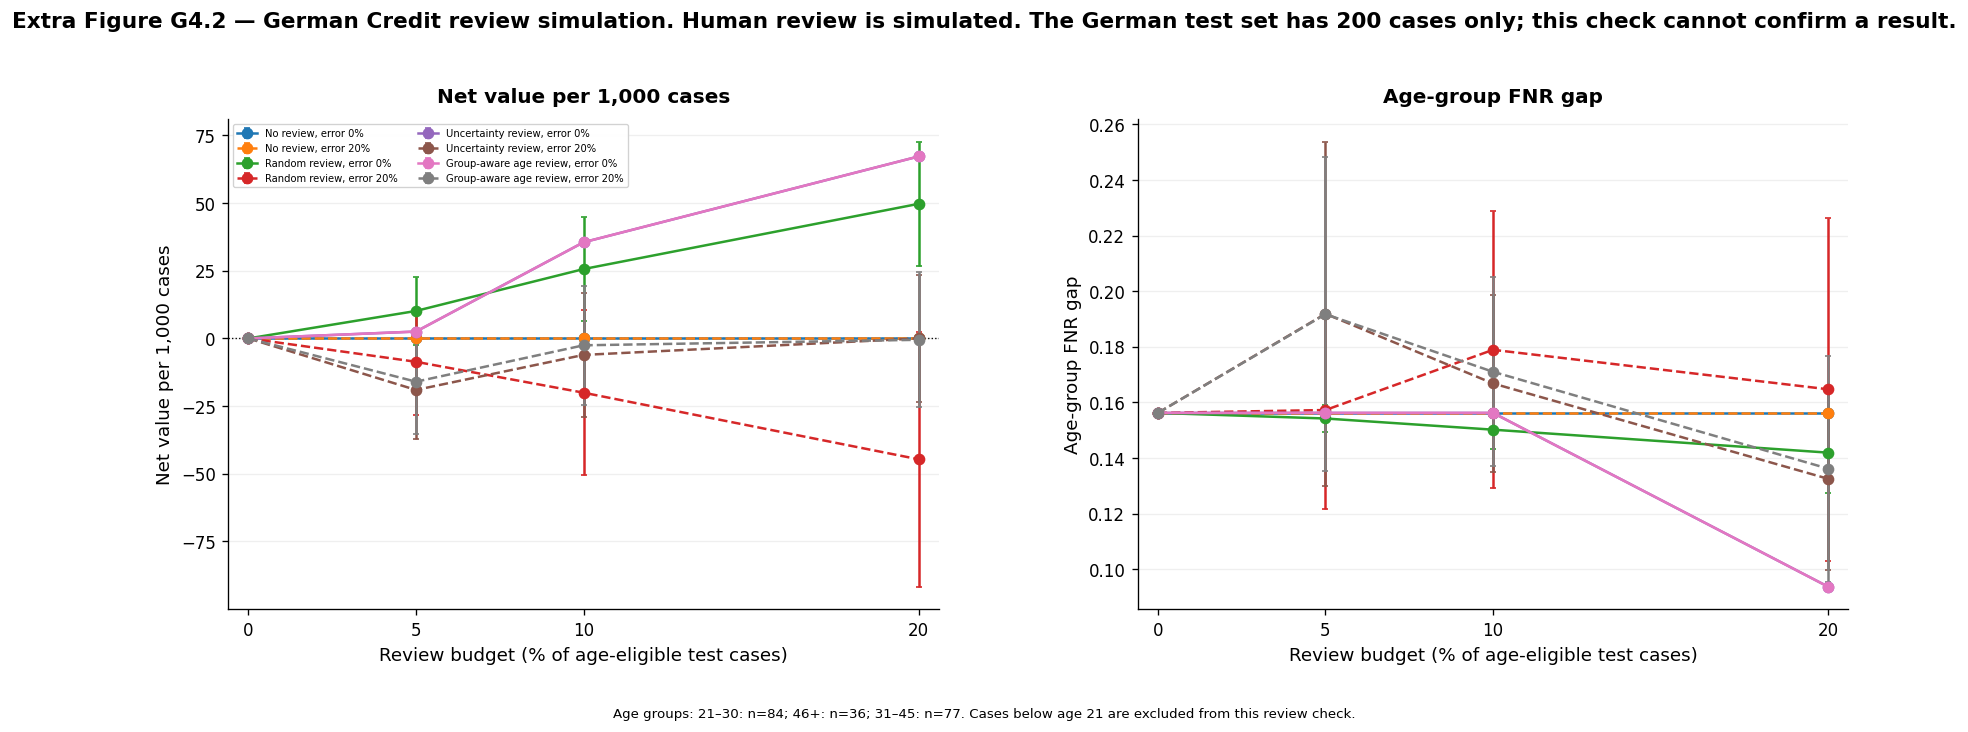

WindowsPath('c:/Users/dheer/Projects/DSC02/PW26 - Interdisciplinary Elective AI, Power & Responsibility – Governing Intell/Dataset/credit_review_work/credit_review_results/figures/Extra_Figure_G4.2.pdf')

In [20]:
# German Credit RQ4 extension. This is a simulation, not observed human review.
german_review_mask = german_test_audit['age'].to_numpy() >= 21
german_y_review = yg_test.to_numpy()[german_review_mask]
german_probs_review = np.asarray(GERMAN_PRIMARY_PROBS, dtype=float)[german_review_mask]
german_age_review_groups = (
    german_test_audit.loc[german_review_mask, 'age_group'].astype(str).to_numpy()
)
GERMAN_REVIEWER_ERROR_RATES = [0.00, 0.20]
german_review_rows = []

for capacity_index, capacity in enumerate(CAPACITY_LEVELS):
    queue_size = int(round(capacity * len(german_y_review)))
    for error_index, error_rate in enumerate(GERMAN_REVIEWER_ERROR_RATES):
        for policy_index, policy in enumerate(POLICIES):
            replicate_metrics = []
            for repetition in range(REVIEW_REPEATS):
                cell_seed = (
                    SEED + 3000000 + capacity_index * 100000 +
                    error_index * 10000 + policy_index * 1000 + repetition
                )
                reviewed = select_policy(
                    policy, german_probs_review, queue_size,
                    age_groups=german_age_review_groups, seed=cell_seed
                )
                metrics, _ = simulate_review(
                    german_y_review, german_probs_review, reviewed,
                    reviewer_error_rate=error_rate,
                    seed=cell_seed + 5000000,
                    age_groups=german_age_review_groups
                )
                replicate_metrics.append(metrics)

            replicate_frame = pd.DataFrame(replicate_metrics)
            german_review_rows.append({
                'dataset': 'Statlog German Credit',
                'selected_model': GERMAN_PRIMARY_NAME,
                'full_test_set_cases': int(len(yg_test)),
                'evaluated_cases_age_21_plus': int(len(german_y_review)),
                'excluded_below_age_21': int((~german_review_mask).sum()),
                'capacity': capacity,
                'policy': policy,
                'reviewer_error_rate': error_rate,
                'repetitions': REVIEW_REPEATS,
                'reviews_mean': float(replicate_frame['n_reviewed'].mean()),
                'net_value_per_1000_mean': float(replicate_frame['net_value_per_1000'].mean()),
                'net_value_per_1000_sd': float(replicate_frame['net_value_per_1000'].std(ddof=1)),
                'age_FNR_gap_mean': float(replicate_frame['age_FNR_gap'].mean()),
                'age_FNR_gap_sd': float(replicate_frame['age_FNR_gap'].std(ddof=1)),
                'age_group_counts': group_count_text(german_age_review_groups)
            })

german_review_results = pd.DataFrame(german_review_rows)
display_and_save('Extra_Table_G4.1', german_review_results)

# Figure G4.2: net value and age FNR gap for both reviewer error rates.
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
line_styles = {0.00: '-', 0.20: '--'}
for ax, metric, error_column, title, ylabel in [
    (axes[0], 'net_value_per_1000_mean', 'net_value_per_1000_sd',
     'Net value per 1,000 cases', 'Net value per 1,000 cases'),
    (axes[1], 'age_FNR_gap_mean', 'age_FNR_gap_sd',
     'Age-group FNR gap', 'Age-group FNR gap')
]:
    for policy in POLICIES:
        for error_rate in GERMAN_REVIEWER_ERROR_RATES:
            frame = german_review_results[
                (german_review_results['policy'] == policy) &
                (german_review_results['reviewer_error_rate'] == error_rate)
            ].sort_values('capacity')
            ax.errorbar(
                frame['capacity'] * 100, frame[metric],
                yerr=frame[error_column], marker='o', capsize=2,
                linestyle=line_styles[error_rate], linewidth=1.5,
                label=f'{policy}, error {error_rate:.0%}'
            )
    if metric == 'net_value_per_1000_mean':
        ax.axhline(0, color='black', linewidth=0.8, linestyle=':')
    ax.set(title=title, xlabel='Review budget (% of age-eligible test cases)', ylabel=ylabel)
    ax.set_xticks([0, 5, 10, 20])
    clean_axis(ax)
axes[0].legend(frameon=False, fontsize=6, ncol=2)
fig.suptitle(
    'Extra Figure G4.2 — German Credit review simulation. Human review is simulated. '
    'The German test set has 200 cases only; this check cannot confirm a result.',
    fontsize=11, fontweight='bold'
)
fig.text(
    0.5, 0.01,
    'Age groups: ' + group_count_text(german_age_review_groups) +
    '. Cases below age 21 are excluded from this review check.',
    ha='center', fontsize=8
)
fig.tight_layout(rect=[0, 0.08, 1, 0.90])
save_figure('Extra_Figure_G4.2', fig)


### Cohort profiles, benchmark figures and limitations

**Purpose:** Save descriptive summaries for both datasets. Show the German ROC curves and age-group error rates. Print the sample count for each age group. Record the limits of the historical labels, combined German field, simulated reviewer and scenario costs.


,dataset,n_rows,n_model_features,positive_label,positive_label_rate,missing_cells
0,UCI Default of Credit Card Clients,30000,23,Next-month default recorded in the source data,0.2212,0
1,Statlog German Credit,1000,20,Source class 2 (bad-risk label),0.3000,16


,group,n,positive_label_rate,grouping
0,Female,18112,0.207763,Recorded sex
1,Male,11888,0.241672,Recorded sex
2,21–30,11013,0.224371,Age group
3,31–45,14318,0.208619,Age group
4,46+,4669,0.252302,Age group


,grouping,group,n,n_positive,n_negative,positive_label_rate,mean_predicted_probability,Brier score,ECE (10 bins),FPR,FNR,precision,positive_prediction_rate,reviewed_n,review_rate,share_of_all_reviews
0,Recorded sex × age group,Male × 21–30,742,167,575,0.225067,0.237950,0.143256,0.040816,0.403478,0.197605,0.366120,0.493261,180,0.242588,0.150000
1,Recorded sex × age group,Female × 46+,557,144,413,0.258528,0.251569,0.143082,0.041771,0.411622,0.229167,0.395018,0.504488,108,0.193896,0.090000
2,Recorded sex × age group,Female × 31–45,1632,311,1321,0.190564,0.201602,0.118917,0.022726,0.342922,0.266881,0.334802,0.417279,295,0.180760,0.245833
3,Recorded sex × age group,Female × 21–30,1439,300,1139,0.208478,0.224474,0.121716,0.025191,0.338016,0.220000,0.378029,0.430160,281,0.195274,0.234167
4,Recorded sex × age group,Male × 31–45,1188,280,908,0.235690,0.223844,0.138933,0.031198,0.332599,0.242857,0.412451,0.432660,237,0.199495,0.197500
5,Recorded sex × age group,Male × 46+,442,125,317,0.282805,0.240521,0.166038,0.055513,0.384858,0.256000,0.432558,0.486425,99,0.223982,0.082500


Sex-by-age sample counts: Male × 21–30: n=742; Female × 46+: n=557; Female × 31–45: n=1,632; Female × 21–30: n=1,439; Male × 31–45: n=1,188; Male × 46+: n=442


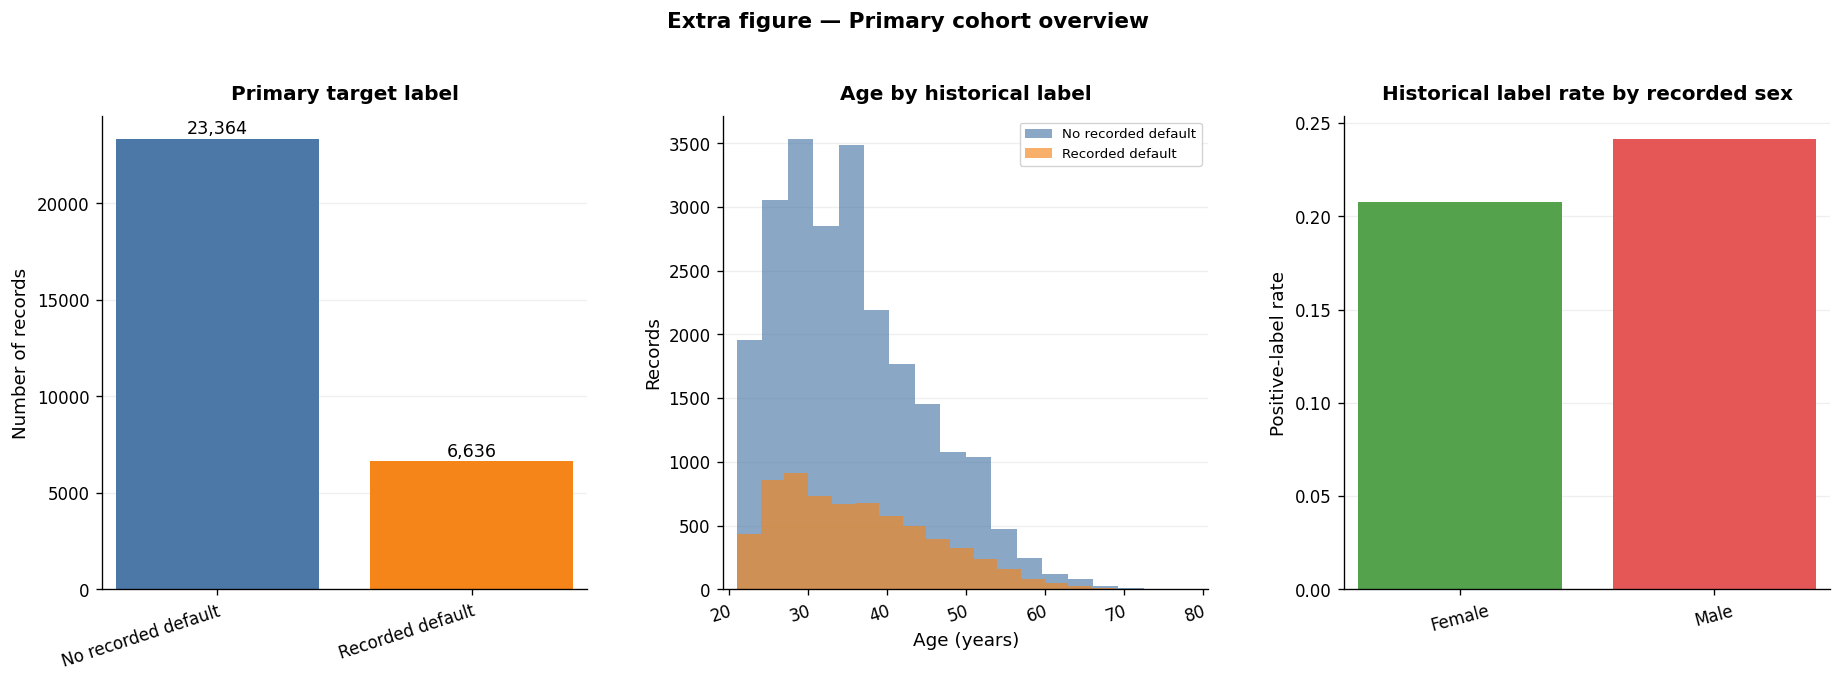

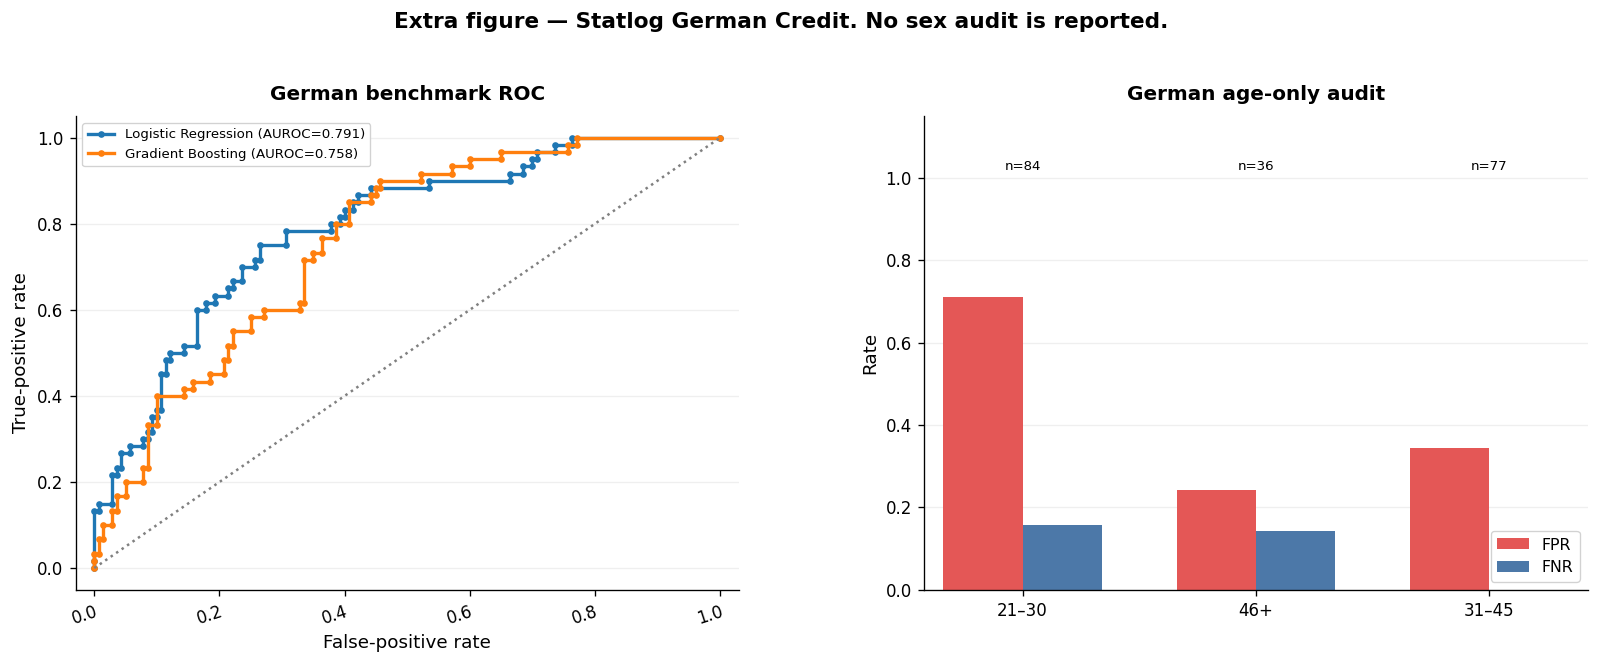

,item,limitation
0,Human review,Human review is simulated. The reviewer sees t...
1,Reviewer errors,Reviewer errors are independent. The same erro...
2,Review cost,The review cost of 0.25 is a scenario assumpti...
3,Primary dataset costs,The false-positive cost of 1 and false-negativ...
4,Historical target,The target records a past outcome. It is not a...
5,German sex field,The German personal_status_sex field mixes sex...
6,German age audit,"The German age audit uses the 21–30, 31–45 and..."
7,Feature importance,Coefficients and permutation importance descri...
8,External benchmark,"The datasets differ in time, geography, popula..."


In [21]:
# Extra Table: cohort profile.
profile_rows = [
    {
        'dataset': 'UCI Default of Credit Card Clients',
        'n_rows': int(len(credit_df)),
        'n_model_features': int(len(FEATURE_COLUMNS)),
        'positive_label': 'Next-month default recorded in the source data',
        'positive_label_rate': float(credit_df[TARGET].mean()),
        'missing_cells': int(credit_df.isna().sum().sum())
    },
    {
        'dataset': 'Statlog German Credit',
        'n_rows': int(len(german_df)),
        'n_model_features': int(len(german_feature_cols)),
        'positive_label': 'Source class 2 (bad-risk label)',
        'positive_label_rate': float(german_df[GERMAN_TARGET].mean()),
        'missing_cells': int(german_df.isna().sum().sum())
    }
]
display_and_save('Extra_Table_dataset_profile', pd.DataFrame(profile_rows))

# Extra Table: primary group counts and observed historical label rates.
primary_group_profile = pd.concat([
    credit_df.groupby('sex_group', observed=False).agg(
        n=(TARGET, 'size'), positive_label_rate=(TARGET, 'mean')
    ).reset_index().rename(columns={'sex_group': 'group'}).assign(grouping='Recorded sex'),
    credit_df.groupby('age_group', observed=False).agg(
        n=(TARGET, 'size'), positive_label_rate=(TARGET, 'mean')
    ).reset_index().rename(columns={'age_group': 'group'}).assign(grouping='Age group')
], ignore_index=True)
display_and_save('Extra_Table_primary_group_profile', primary_group_profile)

# Extra Table: the requested sex-by-age audit. This is not used by the group-aware queue.
intersection_groups = (test_audit['sex_group'].astype(str) + ' × ' +
                       test_audit['age_group'].astype(str))
intersection_audit = group_audit(
    y_test, PRIMARY_PROBS, intersection_groups,
    'Recorded sex × age group', reviewed=rq2_review_flags
)
display_and_save('Extra_Table_sex_by_age_audit', intersection_audit)
print('Sex-by-age sample counts:', group_count_text(intersection_groups))

# Extra Figure: primary cohort overview.
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
target_counts = credit_df[TARGET].value_counts().sort_index()
axes[0].bar(['No recorded default', 'Recorded default'],
            [target_counts.get(0, 0), target_counts.get(1, 0)],
            color=['#4C78A8', '#F58518'])
axes[0].set_title('Primary target label')
axes[0].set_ylabel('Number of records')
for index, value in enumerate([target_counts.get(0, 0), target_counts.get(1, 0)]):
    axes[0].text(index, value + max(target_counts) * 0.01, f'{value:,}', ha='center')
for value, label, color in [(0, 'No recorded default', '#4C78A8'),
                            (1, 'Recorded default', '#F58518')]:
    axes[1].hist(credit_df.loc[credit_df[TARGET] == value, 'AGE'],
                 bins=18, alpha=0.65, label=label, color=color)
axes[1].set(title='Age by historical label', xlabel='Age (years)', ylabel='Records')
axes[1].legend(frameon=False, fontsize=8)
sex_rate = credit_df.groupby('sex_group')[TARGET].mean()
axes[2].bar(sex_rate.index.astype(str), sex_rate.values, color=['#54A24B', '#E45756', '#B279A2'][:len(sex_rate)])
axes[2].set(title='Historical label rate by recorded sex', ylabel='Positive-label rate')
axes[2].tick_params(axis='x', rotation=15)
for ax in axes:
    clean_axis(ax)
fig.suptitle('Extra figure — Primary cohort overview', fontsize=13, fontweight='bold')
fig.tight_layout(rect=[0.02, 0.02, 0.98, 0.87], w_pad=2.5, h_pad=2.0)
save_figure('Extra_Figure_primary_cohort_overview', fig)

# Extra Figure: German ROC curves and age-only error rates.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name, result in german_models.items():
    fpr, tpr, _ = roc_curve(yg_test, result['p_test_cal'])
    auc_value = roc_auc_score(yg_test, result['p_test_cal'])
    axes[0].plot(fpr, tpr, marker='.', linewidth=2,
                 label=f'{name} (AUROC={auc_value:.3f})')
axes[0].plot([0, 1], [0, 1], color='grey', linestyle=':')
axes[0].set(title='German benchmark ROC', xlabel='False-positive rate', ylabel='True-positive rate')
axes[0].legend(frameon=False, fontsize=8)
bar_positions = np.arange(len(german_age_audit))
bar_width = 0.34
axes[1].bar(bar_positions - bar_width / 2, german_age_audit['FPR'],
            bar_width, label='FPR', color='#E45756')
axes[1].bar(bar_positions + bar_width / 2, german_age_audit['FNR'],
            bar_width, label='FNR', color='#4C78A8')
axes[1].set_xticks(bar_positions, german_age_audit['group'])
axes[1].set(title='German age-only audit', ylabel='Rate', ylim=(0, 1.15))
axes[1].legend(frameon=False)
for index, row in german_age_audit.iterrows():
    axes[1].text(index, 1.02, f'n={row["n"]:,}', ha='center', fontsize=8)
for ax in axes:
    clean_axis(ax)
fig.suptitle('Extra figure — Statlog German Credit. No sex audit is reported.',
             fontsize=12, fontweight='bold')
fig.tight_layout(rect=[0.02, 0.02, 0.98, 0.87], w_pad=2.5, h_pad=2.0)
save_figure('Extra_Figure_German_benchmark_age_only', fig)

# Extra Table: study limitations and interpretation rules.
limitations = pd.DataFrame([
    {
        'item': 'Human review',
        'limitation': 'Human review is simulated. The reviewer sees the true label only inside the simulation. No observed reviewer decisions are supplied.'
    },
    {
        'item': 'Reviewer errors',
        'limitation': 'Reviewer errors are independent. The same error rate applies to both classes.'
    },
    {
        'item': 'Review cost',
        'limitation': 'The review cost of 0.25 is a scenario assumption in normalized cost units.'
    },
    {
        'item': 'Primary dataset costs',
        'limitation': 'The false-positive cost of 1 and false-negative cost of 5 are scenario assumptions. They are not observed Taiwan financial losses.'
    },
    {
        'item': 'Historical target',
        'limitation': 'The target records a past outcome. It is not a correct measure of creditworthiness.'
    },
    {
        'item': 'German sex field',
        'limitation': 'The German personal_status_sex field mixes sex and marital status. No German sex audit is reported.'
    },
    {
        'item': 'German age audit',
        'limitation': 'The German age audit uses the 21–30, 31–45 and 46+ groups. Records below age 21 are excluded from this audit.'
    },
    {
        'item': 'Feature importance',
        'limitation': 'Coefficients and permutation importance describe model behaviour. Feature importance is not a causal effect.'
    },
    {
        'item': 'External benchmark',
        'limitation': 'The datasets differ in time, geography, population and feature definitions. Do not compare their absolute risk levels as one population.'
    }
])
display_and_save('Extra_Table_study_limitations', limitations)


### Aggregate-only export safeguard

**Purpose:** Keep the results bundle at aggregate level. Do not save a row-level prediction file. Do not add a row-level prediction file to the ZIP.


In [22]:
print('No row-level prediction file is created or added to the results ZIP.')


No row-level prediction file is created or added to the results ZIP.


## Export and validation — Manifest and results ZIP

**Purpose:** Write `Extra_Table_run_settings.csv`. Create one ZIP that contains PDF figures and CSV tables only. Do not write JSON or Markdown files into the ZIP. Do not include row-level predictions.


In [23]:
# Record all run settings in a CSV table.
import sklearn
import scipy
import matplotlib

run_settings = [
    ('seed', SEED),
    ('library_versions', (
        f"Python {sys.version.split()[0]}; NumPy {np.__version__}; pandas {pd.__version__}; "
        f"scikit-learn {sklearn.__version__}; Matplotlib {matplotlib.__version__}; SciPy {scipy.__version__}"
    )),
    ('primary_split_sizes', (
        f"train={len(idx_train)} ({len(idx_train)/len(credit_df):.0%}); "
        f"validation={len(idx_val)} ({len(idx_val)/len(credit_df):.0%}); "
        f"test={len(idx_test)} ({len(idx_test)/len(credit_df):.0%})"
    )),
    ('german_split_sizes', (
        f"train={len(idxg_train)} ({len(idxg_train)/len(german_df):.0%}); "
        f"validation={len(idxg_val)} ({len(idxg_val)/len(german_df):.0%}); "
        f"test={len(idxg_test)} ({len(idxg_test)/len(german_df):.0%})"
    )),
    ('split_method', '60/20/20; stratified; random_state=42'),
    ('model_settings', (
        'Logistic Regression: max_iter=1200, solver=lbfgs; '
        'Gradient Boosting: HistGradientBoostingClassifier, max_iter=100, learning_rate=0.08, '
        'max_leaf_nodes=15, l2_regularization=1.0, early_stopping=True; '
        'Platt/sigmoid calibration fitted on validation predictions'
    )),
    ('false_negative_cost', FALSE_NEGATIVE_COST),
    ('false_positive_cost', FALSE_POSITIVE_COST),
    ('review_cost_per_case', REVIEW_COST_PER_CASE),
    ('decision_threshold', DECISION_THRESHOLD),
    ('review_budgets', ', '.join(f'{v:.0%}' for v in CAPACITY_LEVELS)),
    ('reviewer_error_rates', ', '.join(f'{v:.0%}' for v in REVIEWER_ERROR_RATES)),
    ('german_reviewer_error_rates', ', '.join(f'{v:.0%}' for v in GERMAN_REVIEWER_ERROR_RATES)),
    ('repetitions_per_simulation_cell', REVIEW_REPEATS),
    ('bootstrap_resamples', BOOTSTRAP_RESAMPLES),
    ('bootstrap_seeds','shared index resamples; 700042 index stream; 8000042 case queue stream; 9000042 reviewer stream'),
    ('operational_model_primary', PRIMARY_MODEL_NAME),
    ('operational_model_german', GERMAN_PRIMARY_NAME),
    ('validation_AUROC_tie_rule', MODEL_TIE_RULE),
    ('german_age_eligible_test_n', len(german_y_review)),
    ('german_below_21_excluded_test_n',int((~german_review_mask).sum())),
    ('rq3_feature_configurations', ', '.join(FEATURE_CONFIGURATIONS.keys())),
    ('age_groups', '21–30; 31–45; 46+'),
    ('group_aware_review', 'Proportional age-group quotas by largest remainder; uncertainty priority within each age group; no sex-based allocation'),
    ('reviewer_model', (
        'Simulated reviewer sees the true label; correct with probability 1 - error rate; '
        'independent symmetric errors; reviewed decision replaces automatic decision'
    )),
    ('target_interpretation', 'The label records a past outcome; it is not a correct measure of creditworthiness.'),
    ('feature_importance_interpretation', 'Feature importance is not a causal effect.')
]
run_settings_frame = pd.DataFrame(run_settings, columns=['setting', 'value'])
display_and_save('Extra_Table_run_settings', run_settings_frame)

# Machine-readable CSV manifest and exact reproducibility checks.
import hashlib
manifest_rows=[]
for path in sorted(RESULTS_DIR.rglob('*')):
    if path.is_file():
        rel=path.relative_to(RESULTS_DIR).as_posix()
        manifest_rows.append({'relative_path':rel,'format':path.suffix.lower(),'bytes':path.stat().st_size,
                              'sha256':hashlib.sha256(path.read_bytes()).hexdigest()})
manifest=pd.DataFrame(manifest_rows)
display_and_save('Extra_Table_export_manifest',manifest)
allowed_suffixes={'.pdf','.csv'}
all_result_files=sorted(path for path in RESULTS_DIR.rglob('*') if path.is_file())
assert all(p.suffix.lower() in allowed_suffixes for p in all_result_files)
assert not any('prediction' in p.name.lower() for p in all_result_files)
assert list(FIG_DIR.glob('*.pdf')) and list(TABLE_DIR.glob('*.csv'))
required_tables=['Table_1.1_model_metrics','Table_2.1_group_rates',
    'Table_3.1_feature_configurations','Table_4.4_reviews_and_corrections',
    'Extra_Table_4.5_paired_policy_differences','Extra_Table_2.5_policy_budget_group_audit',
    'Extra_Table_G4.1','Extra_Table_RQ5_review_simulation_grid',
    'Extra_Table_run_settings','Extra_Table_export_manifest']
for table in required_tables:
    assert (TABLE_DIR/(table+'.csv')).is_file(),table
assert len(FEATURE_CONFIGURATIONS)==6
assert BOOTSTRAP_RESAMPLES==500
assert set(REVIEWER_ERROR_RATES)=={0.,.1,.2,.3,.4}
assert set(GERMAN_REVIEWER_ERROR_RATES)=={0.,.2}
assert set(rq4_reviews_corrections['policy'])==set(POLICIES)
assert rq4_reviews_corrections['bootstrap_resamples'].eq(500).all()
assert rq4_reviews_corrections[['net_value_95_percentile_low','net_value_95_percentile_high','age_FNR_gap_95_percentile_low','age_FNR_gap_95_percentile_high']].notna().all().all()
assert set(rq4_paired['capacity'])=={.05,.1,.2}
assert int((~german_review_mask).sum())+len(german_y_review)==len(yg_test)
for cap in CAPACITY_LEVELS:
  k=int(round(cap*len(y_test)))
  subset=rq4_replicates[rq4_replicates.capacity==cap]
  for pol in POLICIES:
    expected=0 if pol=='No review' else k
    assert (subset.loc[subset.policy==pol,'n_reviewed']==expected).all()
zip_path=WORK_ROOT/'fairness_review_capacity_results.zip'
if zip_path.exists(): zip_path.unlink()
with zipfile.ZipFile(zip_path,'w',compression=zipfile.ZIP_DEFLATED) as archive:
    for path in all_result_files:
        archive.write(path,arcname=path.relative_to(RESULTS_DIR).as_posix())
with zipfile.ZipFile(zip_path) as archive:
    assert archive.testzip() is None
    assert sorted(archive.namelist())==sorted(p.relative_to(RESULTS_DIR).as_posix() for p in all_result_files)
    for path in all_result_files:
        assert archive.read(path.relative_to(RESULTS_DIR).as_posix())==path.read_bytes()
print('Validated fresh archive:',zip_path)
print('PDF figures:',len(list(FIG_DIR.glob('*.pdf'))),'CSV tables:',len(list(TABLE_DIR.glob('*.csv'))))
print('Archive CSV/PDF bytes match displayed and saved source files. No row-level predictions exported.')


,setting,value
0,seed,42
1,library_versions,Python 3.14.3; NumPy 2.4.4; pandas 2.3.3; scik...
2,primary_split_sizes,train=18000 (60%); validation=6000 (20%); test...
3,german_split_sizes,train=600 (60%); validation=200 (20%); test=20...
4,split_method,60/20/20; stratified; random_state=42
5,model_settings,"Logistic Regression: max_iter=1200, solver=lbf..."
6,false_negative_cost,5.0
7,false_positive_cost,1.0
8,review_cost_per_case,0.25
9,decision_threshold,0.166667


,relative_path,format,bytes,sha256
0,figures/Extra_Figure_G4.2.pdf,.pdf,40407,111d4e0ab4f368d29911018a0c83ffe607f7b273f1aa84...
1,figures/Extra_Figure_German_benchmark_age_only...,.pdf,30919,8fcd756afb5930acb5a4e8daf8a480b3bf4b0c93c92746...
2,figures/Extra_Figure_primary_cohort_overview.pdf,.pdf,25791,cdf68f9381914f0c9fcdc36e53962d4164d24e873ae3c2...
3,figures/Figure_1.2_reliability_diagrams.pdf,.pdf,25833,b292481fa2911ba38d7afcf7bdf95ec7d2f3ba77a32890...
4,figures/Figure_1.3_ROC_curves.pdf,.pdf,61508,46365bcb1b339e29bd9ea48547ca44f75d26e31b59468c...
5,figures/Figure_2.2_gap_bars_sex_age.pdf,.pdf,23412,56cc300e4cb3cb018306eb4b645fd8499af66f57a5010c...
6,figures/Figure_2.3_group_reliability_curves.pdf,.pdf,28190,2d2aba05ee879912c6060176971d42c6f3efa9a9bcd9ad...
7,figures/Figure_2.4_review_rate_by_group.pdf,.pdf,26488,0cae58069a28e0de9c9a6dc73a583f760e0ac6f7395436...
8,figures/Figure_3.2_ROC_AUC_drop.pdf,.pdf,25991,64dc58999e7e44fead7a861c807fa3164adc78f5e4d107...
9,figures/Figure_3.3_FNR_gap_by_configuration.pdf,.pdf,29746,610e591027eda58c21c1cb460c408e49160569165809d1...


Validated fresh archive: c:\Users\dheer\Projects\DSC02\PW26 - Interdisciplinary Elective AI, Power & Responsibility – Governing Intell\Dataset\credit_review_work\fairness_review_capacity_results.zip
PDF figures: 16 CSV tables: 21
Archive CSV/PDF bytes match displayed and saved source files. No row-level predictions exported.


## Results and interpretation

Report figures and numerical findings only from CSV and PDF exports generated by the *same completed notebook run*. Before using values in slides or a manuscript, confirm that the displayed tables and figures agree with the exported files. Interpret RQ4 marginal and paired percentile intervals conditionally on the fixed split, assumed costs, and simulated reviewer. Overlapping marginal intervals are not evidence of equivalence or a reduction in disparities.


## Limitations and interpretation
- The two original UCI datasets are analyzed separately. German Credit sex is **not** audited because its source field conflates sex and marital status. Its age-based review denominator excludes ages below 21.
- The simulated reviewer observes the true recorded label and makes independent symmetric mistakes at specified rates. These are scenario assumptions, not empirical human performance.
- False-negative (5), false-positive (1), and review (0.25) costs are dimensionless assumptions, not observed monetary losses.
- The label describes a historical outcome, not a ground-truth creditworthiness judgment. Feature ablations cannot establish causality.
- Fixed-split 500-resample test-set bootstrap intervals quantify conditional sampling variability, not model-selection, temporal, institutional, reviewer, or deployment uncertainty.
- German Credit has only 200 original test observations before age exclusion, so its benchmark results are exploratory.
- Do not call policy effects equivalent, statistically significant, or clearly disparity-reducing without suitable paired evidence and research justification.


## Appendix — Run order and export inventory

Run all cells from top to bottom in a fresh local or Kaggle session. Provide the two original UCI datasets as separate inputs. Do not skip German model fitting or the German review simulation. The last code cell creates `fairness_review_capacity_results.zip` in the selected working output folder.

The ZIP contains PDF figures and CSV tables only.

**PDF figures**
- `Figure_1.2_reliability_diagrams.pdf`
- `Figure_1.3_ROC_curves.pdf`
- `Figure_2.2_gap_bars_sex_age.pdf`
- `Figure_2.3_group_reliability_curves.pdf`
- `Figure_2.4_review_rate_by_group.pdf`
- `Figure_3.2_ROC_AUC_drop.pdf`
- `Figure_3.3_FNR_gap_by_configuration.pdf`
- `Figure_3.4_coefficients_permutation_importance.pdf`
- `Figure_4.1_net_value_by_budget.pdf`
- `Figure_4.2_FNR_gap_by_budget.pdf`
- `Figure_4.3_value_vs_age_FNR_gap.pdf`
- `Figure_5.1_net_value_by_reviewer_error.pdf`
- `Figure_5.2_age_FNR_gap_by_reviewer_error.pdf`
- `Extra_Figure_primary_cohort_overview.pdf`
- `Extra_Figure_German_benchmark_age_only.pdf`
- `Extra_Figure_G4.2.pdf`

**CSV tables**
- `Table_1.1_model_metrics.csv`
- `Table_1.4_review_queue_overlap.csv`
- `Table_2.1_group_rates.csv`
- `Table_3.1_feature_configurations.csv`
- `Table_4.4_reviews_and_corrections.csv`
- `Extra_Table_RQ5_review_simulation_grid.csv` (aggregate rows only; corrections and changes labeled separately)
- `Table_5.3_break_even_reviewer_error_rate.csv`
- `Table_5.4_policy_ranks.csv`
- `Extra_Table_German_benchmark_metrics.csv`
- `Extra_Table_German_age_audit.csv`
- `Extra_Table_G4.1.csv`
- `Extra_Table_dataset_profile.csv`
- `Extra_Table_primary_group_profile.csv`
- `Extra_Table_sex_by_age_audit.csv`
- `Extra_Table_study_limitations.csv`
- `Extra_Table_run_settings.csv`

The ZIP does not include JSON, Markdown, or row-level prediction files. Human review is simulated. The reviewer sees the true label inside the simulation. The costs are assumptions. The labels record past outcomes. The German test set is small. The results do not show causes.
